| Nama              | NRP        |
|-------------------|------------|
| Muhammad Dayyan Ghazanfar Latief         | 5054241036     |

<center><strong>Deep Learning : Computer Vision</strong><br />
<strong><font color="blue">Departemen Informatika - Prodi RKA - Institut Teknologi Sepuluh Nopember</font></strong><br />
</center>

<strong>Outline Hands-On: Image Segmentation with U-Net</strong><br />
<li> Konsep Image Segmentation & Perbedaan dengan Task CV Lainnya </li>
<li> Arsitektur U-Net (Encoder-Decoder + Skip Connections) </li>
<li> Implementasi U-Net dari Scratch dengan Dataset Oxford-IIIT Pet </li>
<li> Transfer Learning untuk Segmentation: U-Net + MobileNetV2 Backbone </li>
<li> Data Augmentation untuk Segmentation </li>
<li> Evaluasi Mendalam: IoU, Dice Coefficient & Analisis Per-Kelas </li>

---

## Setup & Persiapan Environment

<p><strong><font color="red">PENTING:</font></strong> Pastikan runtime Google Colab menggunakan <strong>GPU</strong> untuk mempercepat proses training.</p>

<p>Cara mengaktifkan GPU di Google Colab:</p>
<ol>
    <li>Klik menu <strong>Runtime</strong> → <strong>Change runtime type</strong></li>
    <li>Pada <strong>Hardware accelerator</strong>, pilih <strong>GPU (T4)</strong></li>
    <li>Klik <strong>Save</strong></li>
</ol>

In [1]:
# Import library yang dibutuhkan
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2

import tensorflow_datasets as tfds

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {tf.config.list_physical_devices('GPU')}")

TensorFlow version: 2.19.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# Fungsi helper untuk memplot training history
def plot_history(history, title=''):
    """Plot accuracy & loss dari training history."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    ax1.plot(history.history['accuracy'], 'b-', label='Training', linewidth=2)
    ax1.plot(history.history['val_accuracy'], 'r-', label='Validation', linewidth=2)
    ax1.set_title(f'Accuracy History {title}', fontsize=13, fontweight='bold')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Accuracy')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    ax2.plot(history.history['loss'], 'b-', label='Training', linewidth=2)
    ax2.plot(history.history['val_loss'], 'r-', label='Validation', linewidth=2)
    ax2.set_title(f'Loss History {title}', fontsize=13, fontweight='bold')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Loss')
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

---
## 1. Image Segmentation: Konsep & Semantic Segmentation

<p><strong>Image Segmentation</strong> adalah task Computer Vision yang bertujuan untuk <strong>mengklasifikasikan setiap piksel</strong> dalam sebuah gambar ke dalam kategori tertentu — bukan hanya seluruh gambar (Classification) atau kotak bounding box (Detection).</p>

### Perbedaan Task Computer Vision:

<table border="1" cellpadding="8" cellspacing="0">
<tr><th>Task</th><th>Output</th><th>Contoh</th></tr>
<tr><td><strong>Classification</strong></td><td>1 label untuk seluruh gambar</td><td>"Kucing"</td></tr>
<tr><td><strong>Object Detection</strong></td><td>Label + koordinat bounding box</td><td>"Kucing" di [x1,y1,x2,y2]</td></tr>
<tr><td><strong>Semantic Segmentation</strong></td><td>Label per-piksel (semua objek sama kelas = warna sama)</td><td>Semua piksel kucing = warna kuning</td></tr>
<tr><td><strong>Instance Segmentation</strong></td><td>Label + mask per-objek individual</td><td>Kucing-1 = merah, Kucing-2 = biru</td></tr>
</table>

### Arsitektur Utama untuk Segmentation:

<ol>
    <li><strong>FCN (Fully Convolutional Network)</strong> — Pertama mengganti Dense layer dengan Conv layer, sehingga bisa menghasilkan output berupa spatial map</li>
    <li><strong>U-Net</strong> — Arsitektur <em>encoder-decoder</em> dengan <em>skip connections</em>; sangat populer untuk medical imaging</li>
    <li><strong>DeepLab</strong> — Menggunakan <em>dilated/atrous convolution</em> untuk memperluas receptive field tanpa mengurangi resolusi</li>
    <li><strong>Mask R-CNN</strong> — Ekstensi dari Faster R-CNN untuk instance segmentation</li>
</ol>

### Arsitektur U-Net:

<p>U-Net terdiri dari dua bagian utama:</p>
<ul>
    <li><strong>Encoder (Contracting Path)</strong> — Seperti CNN biasa: Conv + MaxPool secara berulang → gambar mengecil, fitur semakin abstrak</li>
    <li><strong>Decoder (Expanding Path)</strong> — Kebalikannya: UpSampling/Transpose Conv untuk membesarkan kembali ke ukuran asli</li>
    <li><strong>Skip Connections</strong> — Menghubungkan langsung layer encoder ke decoder pada resolusi yang sama → mempertahankan detail spasial</li>
</ul>

```
Input → [Encoder] → Bottleneck → [Decoder] → Output Mask
            ↑___________skip connections__________↑
```


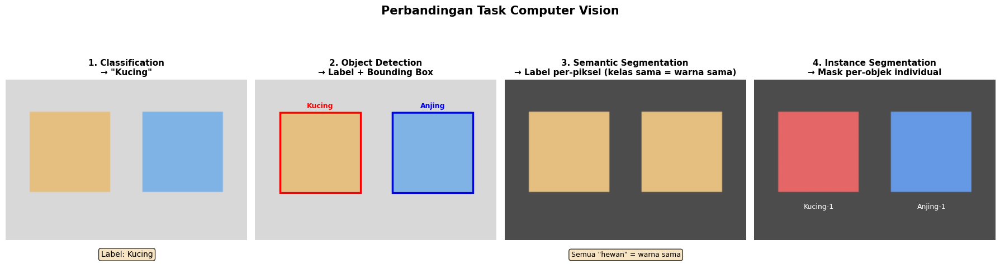

Catatan: Semantic Segmentation = semua objek kelas yang sama → warna sama
         Instance Segmentation = setiap objek individual → warna berbeda


In [3]:
# Visualisasi konsep perbedaan task Computer Vision
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
fig.suptitle('Perbandingan Task Computer Vision', fontsize=15, fontweight='bold', y=1.02)

# Buat gambar sederhana sebagai ilustrasi (2 objek: persegi panjang = kucing & anjing)
base_img = np.ones((100, 150, 3)) * 0.85  # background abu-abu
base_img[20:70, 15:65] = [0.9, 0.75, 0.5]   # objek 1 (kucing) - oranye
base_img[20:70, 85:135] = [0.5, 0.7, 0.9]   # objek 2 (anjing) - biru

# --- 1. Classification ---
axes[0].imshow(base_img)
axes[0].set_title('1. Classification\n→ "Kucing"', fontsize=11, fontweight='bold')
axes[0].text(75, 110, 'Label: Kucing', ha='center', fontsize=10,
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
axes[0].axis('off')

# --- 2. Object Detection ---
axes[1].imshow(base_img)
axes[1].set_title('2. Object Detection\n→ Label + Bounding Box', fontsize=11, fontweight='bold')
rect1 = mpatches.Rectangle((15, 20), 50, 50, linewidth=2.5, edgecolor='red', facecolor='none')
rect2 = mpatches.Rectangle((85, 20), 50, 50, linewidth=2.5, edgecolor='blue', facecolor='none')
axes[1].add_patch(rect1)
axes[1].add_patch(rect2)
axes[1].text(40, 17, 'Kucing', color='red', fontsize=9, fontweight='bold', ha='center')
axes[1].text(110, 17, 'Anjing', color='blue', fontsize=9, fontweight='bold', ha='center')
axes[1].axis('off')

# --- 3. Semantic Segmentation ---
sem_img = np.ones((100, 150, 3)) * 0.3  # background gelap
sem_img[20:70, 15:65] = [0.9, 0.75, 0.5]   # kedua objek warna SAMA (sama-sama hewan)
sem_img[20:70, 85:135] = [0.9, 0.75, 0.5]  # warna sama karena kelas sama
axes[2].imshow(sem_img)
axes[2].set_title('3. Semantic Segmentation\n→ Label per-piksel (kelas sama = warna sama)', fontsize=11, fontweight='bold')
axes[2].text(75, 110, 'Semua "hewan" = warna sama', ha='center', fontsize=9,
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
axes[2].axis('off')

# --- 4. Instance Segmentation ---
inst_img = np.ones((100, 150, 3)) * 0.3
inst_img[20:70, 15:65] = [0.9, 0.4, 0.4]   # objek 1 = merah
inst_img[20:70, 85:135] = [0.4, 0.6, 0.9]  # objek 2 = biru (berbeda walau kelas sama)
axes[3].imshow(inst_img)
axes[3].set_title('4. Instance Segmentation\n→ Mask per-objek individual', fontsize=11, fontweight='bold')
axes[3].text(40, 80, 'Kucing-1', color='white', fontsize=9, ha='center')
axes[3].text(110, 80, 'Anjing-1', color='white', fontsize=9, ha='center')
axes[3].axis('off')

plt.tight_layout()
plt.show()
print("Catatan: Semantic Segmentation = semua objek kelas yang sama → warna sama")
print("         Instance Segmentation = setiap objek individual → warna berbeda")


### Implementasi U-Net Sederhana

<p>Kita akan mengimplementasikan U-Net sederhana menggunakan dataset <strong>Oxford-IIIT Pet</strong> yang sudah tersedia di TensorFlow Datasets. Dataset ini berisi:</p>
<ul>
    <li>~7.400 gambar hewan peliharaan (37 jenis kucing & anjing)</li>
    <li>Setiap gambar sudah memiliki <strong>segmentation mask</strong> (3 kelas: objek, background, border)</li>
</ul>

<p><strong>Arsitektur U-Net yang akan kita bangun:</strong></p>
<pre>
Input (128×128×3)
  ↓
[Encoder]
  Conv(64) → Conv(64) → MaxPool  → skip1 (128×128×64)
  Conv(128) → Conv(128) → MaxPool → skip2 (64×64×128)
  Conv(256) → Conv(256) → MaxPool → skip3 (32×32×256)
  ↓
[Bottleneck]
  Conv(512) → Conv(512)           (16×16×512)
  ↓
[Decoder]
  UpSample + skip3 → Conv(256) → Conv(256)  (32×32×256)
  UpSample + skip2 → Conv(128) → Conv(128)  (64×64×128)
  UpSample + skip1 → Conv(64)  → Conv(64)   (128×128×64)
  ↓
Output Conv(3, softmax)          (128×128×3 → 3 kelas)
</pre>


In [4]:
# Install tensorflow-datasets jika belum tersedia
# !pip install tensorflow-datasets -q

import tensorflow_datasets as tfds
import tensorflow as tf

# Load Oxford-IIIT Pet dataset
print("Mengunduh dataset Oxford-IIIT Pet...")
dataset, info = tfds.load('oxford_iiit_pet:4.0.0', with_info=True)  # ← ganti 3.*.* jadi 4.0.0

print(f"\nInfo dataset:")
print(f"  Splits tersedia : {list(dataset.keys())}")
print(f"  Jumlah train    : {info.splits['train'].num_examples}")
print(f"  Jumlah test     : {info.splits['test'].num_examples}")
print(f"  Fitur           : {info.features}")

Mengunduh dataset Oxford-IIIT Pet...


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.WOVLQY_4.0.0/oxford_iiit_pet-train.tfrecord*...…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.WOVLQY_4.0.0/oxford_iiit_pet-test.tfrecord*...:…

Dataset oxford_iiit_pet downloaded and prepared to /root/tensorflow_datasets/oxford_iiit_pet/4.0.0. Subsequent calls will reuse this data.

Info dataset:
  Splits tersedia : ['train', 'test']
  Jumlah train    : 3680
  Jumlah test     : 3669
  Fitur           : FeaturesDict({
    'file_name': Text(shape=(), dtype=string),
    'head_bbox': BBoxFeature(shape=(4,), dtype=float32),
    'image': Image(shape=(None, None, 3), dtype=uint8),
    'label': ClassLabel(shape=(), dtype=int64, num_classes=37),
    'segmentation_mask': Image(shape=(None, None, 1), dtype=uint8),
    'species': ClassLabel(shape=(), dtype=int64, num_classes=2),
})


In [5]:
# Preprocessing: resize gambar & mask ke 128x128
IMG_SIZE = 128
BATCH_SIZE = 32

def preprocess(datapoint):
    """Resize gambar dan mask, normalisasi gambar."""
    # Gambar input: resize ke 128x128, normalisasi ke [0,1]
    image = tf.image.resize(datapoint['image'], (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32) / 255.0

    # Mask: resize ke 128x128
    # Label Oxford Pet: 1=foreground(hewan), 2=background, 3=border
    # Kita shift ke 0-based: 0=hewan, 1=background, 2=border
    mask = tf.image.resize(datapoint['segmentation_mask'], (IMG_SIZE, IMG_SIZE),
                           method='nearest')  # nearest agar label tidak interpolasi
    mask = tf.cast(mask, tf.int32) - 1  # shift: [1,2,3] → [0,1,2]

    return image, mask

# Build dataset pipeline
train_dataset = (dataset['train']
                 .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
                 .shuffle(1000)
                 .batch(BATCH_SIZE)
                 .prefetch(tf.data.AUTOTUNE))

test_dataset = (dataset['test']
                .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
                .batch(BATCH_SIZE)
                .prefetch(tf.data.AUTOTUNE))

print("Dataset siap!")
print(f"Contoh shape: image={list(train_dataset)[0][0].shape}, mask={list(train_dataset)[0][1].shape}")


Dataset siap!
Contoh shape: image=(32, 128, 128, 3), mask=(32, 128, 128, 1)


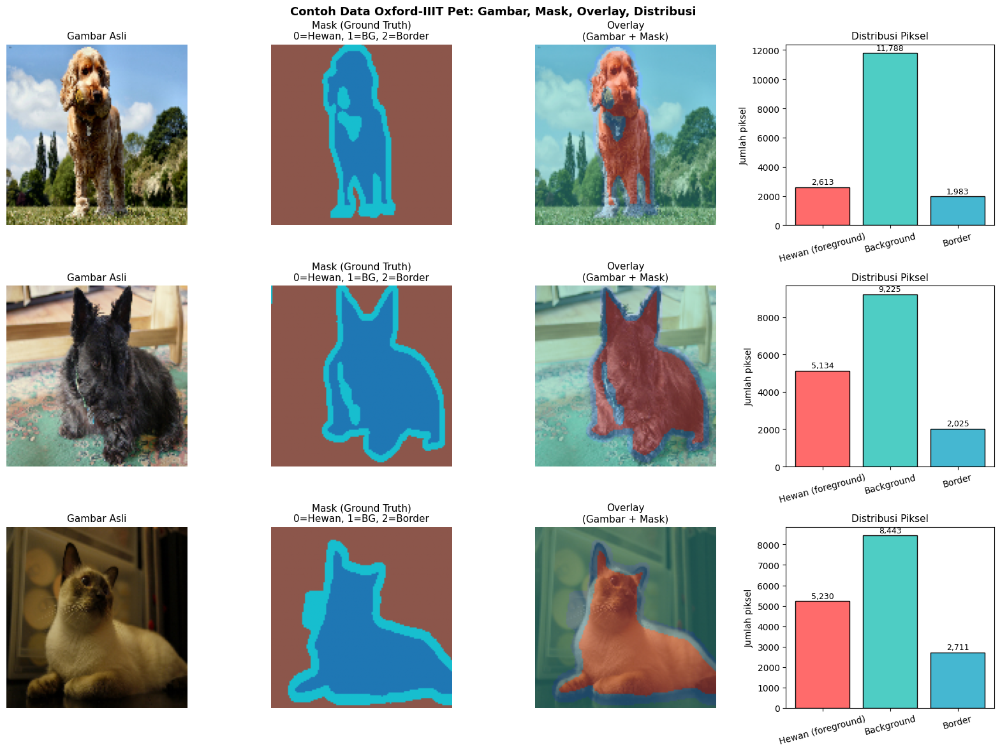

In [6]:
# Visualisasi contoh gambar dan mask-nya
class_labels = ['Hewan (foreground)', 'Background', 'Border']
class_colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']  # merah, hijau, biru

sample_images, sample_masks = next(iter(train_dataset))

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for i in range(3):
    # Gambar asli
    axes[i, 0].imshow(sample_images[i])
    axes[i, 0].set_title('Gambar Asli', fontsize=11)
    axes[i, 0].axis('off')

    # Mask ground truth
    axes[i, 1].imshow(sample_masks[i, :, :, 0], cmap='tab10', vmin=0, vmax=2)
    axes[i, 1].set_title('Mask (Ground Truth)\n0=Hewan, 1=BG, 2=Border', fontsize=11)
    axes[i, 1].axis('off')

    # Overlay: gambar + mask
    mask_rgb = np.zeros((*sample_masks[i, :, :, 0].shape, 3))
    mask_rgb[sample_masks[i, :, :, 0] == 0] = [1, 0.4, 0.4]    # merah = hewan
    mask_rgb[sample_masks[i, :, :, 0] == 1] = [0.3, 0.8, 0.75] # hijau = background
    mask_rgb[sample_masks[i, :, :, 0] == 2] = [0.3, 0.7, 1.0]  # biru = border

    overlay = sample_images[i].numpy() * 0.6 + mask_rgb * 0.4
    axes[i, 2].imshow(np.clip(overlay, 0, 1))
    axes[i, 2].set_title('Overlay\n(Gambar + Mask)', fontsize=11)
    axes[i, 2].axis('off')

    # Distribusi piksel per kelas
    mask_flat = sample_masks[i, :, :, 0].numpy().flatten()
    counts = [np.sum(mask_flat == c) for c in range(3)]
    bars = axes[i, 3].bar(class_labels, counts,
                          color=['#FF6B6B', '#4ECDC4', '#45B7D1'], edgecolor='black')
    axes[i, 3].set_title('Distribusi Piksel', fontsize=11)
    axes[i, 3].set_ylabel('Jumlah piksel')
    axes[i, 3].tick_params(axis='x', rotation=15)
    for bar, count in zip(bars, counts):
        axes[i, 3].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
                        f'{count:,}', ha='center', va='bottom', fontsize=9)

plt.suptitle('Contoh Data Oxford-IIIT Pet: Gambar, Mask, Overlay, Distribusi',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### Membangun Arsitektur U-Net

<p>Kita menggunakan <strong>Functional API</strong> Keras (bukan Sequential) karena U-Net memiliki <em>skip connections</em> — koneksi langsung dari encoder ke decoder yang tidak bisa direpresentasikan secara sequential.</p>

In [7]:
from tensorflow.keras import layers, Model

def conv_block(x, filters, kernel_size=3):
    """Blok 2x Conv2D + ReLU — unit dasar encoder & decoder U-Net."""
    x = layers.Conv2D(filters, kernel_size, padding='same', activation='relu')(x)
    x = layers.Conv2D(filters, kernel_size, padding='same', activation='relu')(x)
    return x

def build_unet(input_shape=(128, 128, 3), num_classes=3):
    """Membangun arsitektur U-Net dengan skip connections."""
    inputs = layers.Input(shape=input_shape)

    # ── ENCODER (Contracting Path) ───────────────────────────────────────
    # Setiap level: 2x Conv → simpan skip → MaxPool (ukuran mengecil ½)
    e1 = conv_block(inputs, 64)          # output: 128×128×64
    p1 = layers.MaxPooling2D(2)(e1)      # output: 64×64×64

    e2 = conv_block(p1, 128)             # output: 64×64×128
    p2 = layers.MaxPooling2D(2)(e2)      # output: 32×32×128

    e3 = conv_block(p2, 256)             # output: 32×32×256
    p3 = layers.MaxPooling2D(2)(e3)      # output: 16×16×256

    # ── BOTTLENECK ────────────────────────────────────────────────────────
    b = conv_block(p3, 512)              # output: 16×16×512

    # ── DECODER (Expanding Path) ──────────────────────────────────────────
    # Setiap level: UpSampling2D (ukuran membesar 2x) → gabung skip → 2x Conv
    d1 = layers.UpSampling2D(2)(b)              # 16×16 → 32×32
    d1 = layers.Concatenate()([d1, e3])         # gabung dengan skip e3
    d1 = conv_block(d1, 256)                    # output: 32×32×256

    d2 = layers.UpSampling2D(2)(d1)             # 32×32 → 64×64
    d2 = layers.Concatenate()([d2, e2])         # gabung dengan skip e2
    d2 = conv_block(d2, 128)                    # output: 64×64×128

    d3 = layers.UpSampling2D(2)(d2)             # 64×64 → 128×128
    d3 = layers.Concatenate()([d3, e1])         # gabung dengan skip e1
    d3 = conv_block(d3, 64)                     # output: 128×128×64

    # ── OUTPUT LAYER ──────────────────────────────────────────────────────
    # 1×1 Conv untuk mapping ke jumlah kelas (per-piksel classification)
    outputs = layers.Conv2D(num_classes, 1, activation='softmax')(d3)  # 128×128×3

    return Model(inputs, outputs, name='U-Net')

model_unet = build_unet(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=3)
model_unet.summary()


Model: "U-Net"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │      1,792 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │     36,928 │ conv2d[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     73,856 │ max_pooling2d[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │    147,584 │ conv2d_2[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │    295,168 │ max_pooling2d_1[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │    590,080 │ conv2d_4[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 16,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 16, 16,    │  1,180,160 │ max_pooling2d_2[… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 16, 16,    │  2,359,808 │ conv2d_6[0][0]    │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 32, 32,    │          0 │ conv2d_7[0][0]    │
│ (UpSampling2D)      │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 32, 32,    │          0 │ up_sampling2d[0]… │
│ (Concatenate)       │ 768)              │            │ conv2d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 32, 32,    │  1,769,728 │ concatenate[0][0] │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 32, 32,    │    590,080 │ conv2d_8[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_1     │ (None, 64, 64,    │          0 │ conv2d_9[0][0]  

 Total params: 7,783,043 (29.69 MB)

 Trainable params: 7,783,043 (29.69 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Compile U-Net
# sparse_categorical_crossentropy → label berupa integer (bukan one-hot)
model_unet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Early stopping agar tidak overfitting
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True
)

print("Memulai training U-Net...")
history_unet = model_unet.fit(
    train_dataset,
    epochs=10,
    validation_data=test_dataset,
    callbacks=[early_stop],
    verbose=1
)

# Evaluasi
test_loss_unet, test_acc_unet = model_unet.evaluate(test_dataset, verbose=0)
print(f"\nTest Accuracy U-Net: {test_acc_unet:.4f}")


Memulai training U-Net...
Epoch 1/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 141s 772ms/step - accuracy: 0.6386 - loss: 0.8380 - val_accuracy: 0.7041 - val_loss: 0.7590
Epoch 2/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 65s 542ms/step - accuracy: 0.7209 - loss: 0.7020 - val_accuracy: 0.7307 - val_loss: 0.6707
Epoch 3/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 65s 544ms/step - accuracy: 0.7562 - loss: 0.6034 - val_accuracy: 0.7727 - val_loss: 0.5583
Epoch 4/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 65s 545ms/step - accuracy: 0.7901 - loss: 0.5262 - val_accuracy: 0.7947 - val_loss: 0.5191
Epoch 5/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 65s 544ms/step - accuracy: 0.8076 - loss: 0.4870 - val_accuracy: 0.7895 - val_loss: 0.5283
Epoch 6/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 69s 584ms/step - accuracy: 0.8216 - loss: 0.4518 - val_accuracy: 0.8294 - val_loss: 0.4346
Epoch 7/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 66s 549ms/step - accuracy: 0.8343 - loss: 0.4230 - val_accuracy: 0.8352 - val_loss: 0.4236
Epoch 8/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 65s 545ms/step -

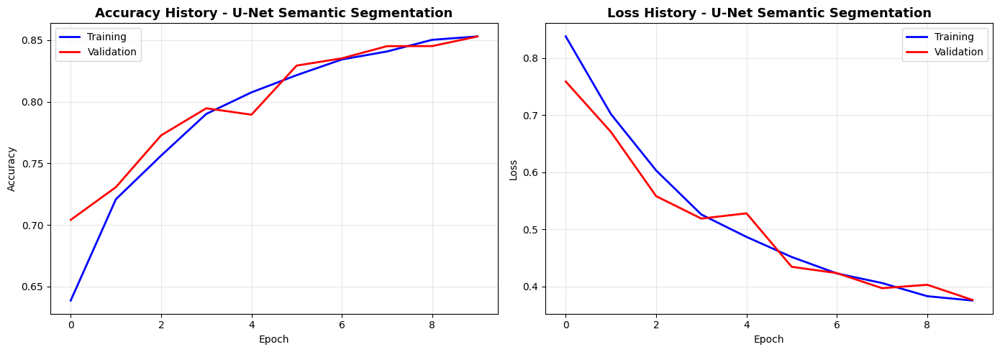

In [9]:
# Plot training history
plot_history(history_unet, '- U-Net Semantic Segmentation')

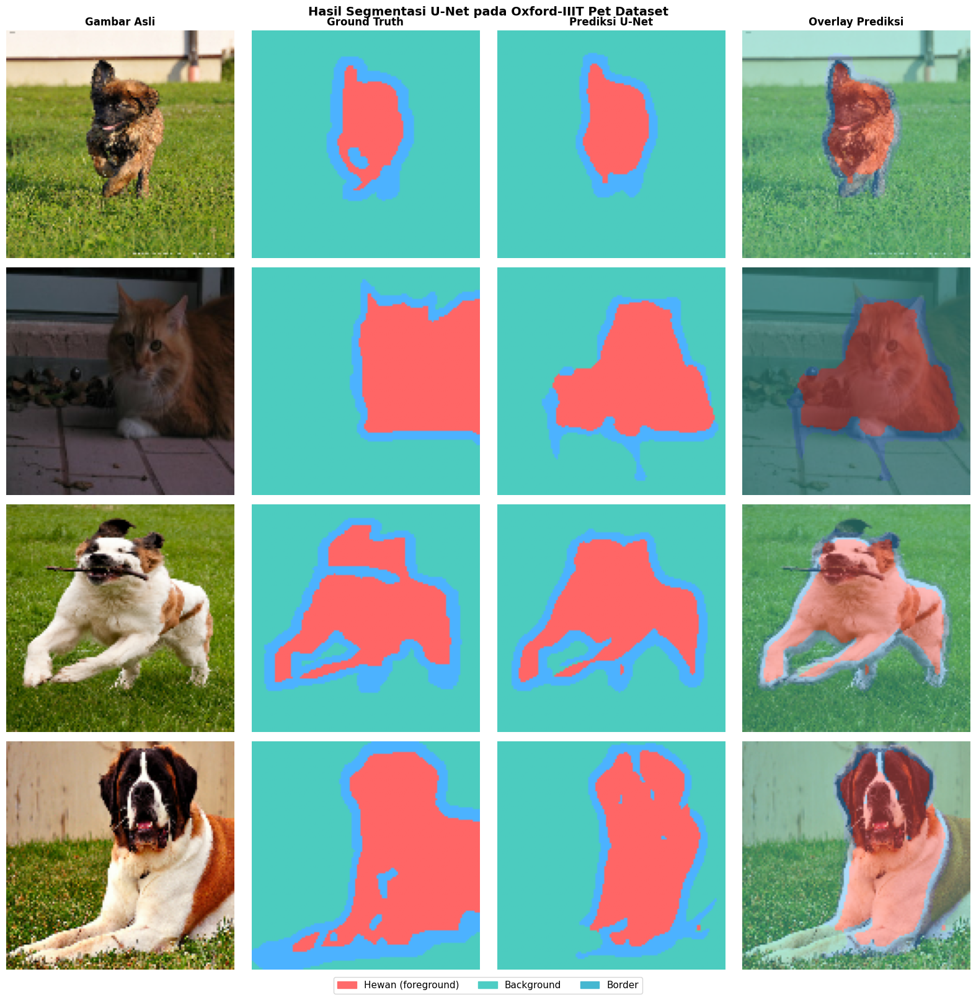

In [10]:
# Visualisasi hasil prediksi U-Net
def visualize_segmentation(model, dataset, num_samples=4):
    """Tampilkan perbandingan: Gambar Asli | Ground Truth | Prediksi | Overlay."""
    sample_images, sample_masks = next(iter(dataset))
    predictions = model.predict(sample_images[:num_samples], verbose=0)
    pred_masks = np.argmax(predictions, axis=-1)  # ambil kelas dengan prob tertinggi

    fig, axes = plt.subplots(num_samples, 4, figsize=(16, num_samples * 4))
    col_titles = ['Gambar Asli', 'Ground Truth', 'Prediksi U-Net', 'Overlay Prediksi']

    for col, title in enumerate(col_titles):
        axes[0, col].set_title(title, fontsize=12, fontweight='bold')

    def mask_to_rgb(mask_2d):
        """Konversi mask integer ke RGB untuk visualisasi."""
        rgb = np.zeros((*mask_2d.shape, 3))
        rgb[mask_2d == 0] = [1.0, 0.4, 0.4]    # merah  = hewan
        rgb[mask_2d == 1] = [0.3, 0.8, 0.75]   # hijau  = background
        rgb[mask_2d == 2] = [0.3, 0.7, 1.0]    # biru   = border
        return rgb

    for i in range(num_samples):
        img = sample_images[i].numpy()
        gt_mask = sample_masks[i, :, :, 0].numpy()
        pred_mask = pred_masks[i]

        # Gambar asli
        axes[i, 0].imshow(img)
        axes[i, 0].axis('off')

        # Ground truth
        axes[i, 1].imshow(mask_to_rgb(gt_mask))
        axes[i, 1].axis('off')

        # Prediksi
        axes[i, 2].imshow(mask_to_rgb(pred_mask))
        axes[i, 2].axis('off')

        # Overlay prediksi di atas gambar asli
        overlay = img * 0.55 + mask_to_rgb(pred_mask) * 0.45
        axes[i, 3].imshow(np.clip(overlay, 0, 1))
        axes[i, 3].axis('off')

    # Legend
    legend_patches = [
        mpatches.Patch(color='#FF6B6B', label='Hewan (foreground)'),
        mpatches.Patch(color='#4ECDC4', label='Background'),
        mpatches.Patch(color='#45B7D1', label='Border'),
    ]
    fig.legend(handles=legend_patches, loc='lower center', ncol=3,
               fontsize=11, bbox_to_anchor=(0.5, -0.02))

    plt.suptitle('Hasil Segmentasi U-Net pada Oxford-IIIT Pet Dataset',
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

visualize_segmentation(model_unet, test_dataset, num_samples=4)


<h3><font color="blue">Latihan 1:</font></h3>

<ul>
    <li>Perhatikan arsitektur U-Net yang sudah dibangun. <strong>Apa fungsi dari <code>layers.Concatenate()</code></strong> pada bagian decoder? Apa yang terjadi jika skip connections dihapus?</li>
    <li>Coba tambahkan satu level encoder-decoder lagi (Conv(512) → MaxPool, lalu UpSample + skip → Conv(512)). Hitung berapa jumlah parameter yang bertambah.</li>
    <li>Mengapa pada segmentation kita menggunakan <code>sparse_categorical_crossentropy</code> bukan <code>categorical_crossentropy</code> seperti di klasifikasi sebelumnya?</li>
</ul>

<p><strong>Hint:</strong> <code>categorical_crossentropy</code> membutuhkan label dalam format one-hot encoding, sedangkan <code>sparse_categorical_crossentropy</code> menerima label berupa integer langsung.</p>


In [15]:
# Kerjakan Latihan 1 pada cell berikut ini

print("--- Pertanyaan 1 ---")
print("Fungsi layers.Concatenate() berfungsi sebagai 'Skip Connections' untuk mengirim detail spasial (resolusi tinggi) dari encoder ke decoder.")
print("Jika dihapus, mask segmentasi akan kabur dan tidak presisi karena model kehilangan detail lokasi (batas tepi) di layer bottleneck.\n")

--- Pertanyaan 1 ---
Fungsi layers.Concatenate() berfungsi sebagai 'Skip Connections' untuk mengirim detail spasial (resolusi tinggi) dari encoder ke decoder.
Jika dihapus, mask segmentasi akan kabur dan tidak presisi karena model kehilangan detail lokasi (batas tepi) di layer bottleneck.



In [14]:
print("--- Pertanyaan 2 ---")
print("Berikut adalah implementasi penambahan satu level encoder-decoder (Conv(512)):")

def build_unet_extended(input_shape=(128, 128, 3), num_classes=3):
    """Membangun arsitektur U-Net yang lebih dalam dengan tambahan 1 level."""
    inputs = layers.Input(shape=input_shape)

    # ── ENCODER ──────────────────────────────────────────────────────────
    e1 = conv_block(inputs, 64)          # output: 128×128×64
    p1 = layers.MaxPooling2D(2)(e1)      # output: 64×64×64

    e2 = conv_block(p1, 128)             # output: 64×64×128
    p2 = layers.MaxPooling2D(2)(e2)      # output: 32×32×128

    e3 = conv_block(p2, 256)             # output: 32×32×256
    p3 = layers.MaxPooling2D(2)(e3)      # output: 16×16×256

    # >>> TAMBAHAN 1 LEVEL ENCODER <<<
    e4 = conv_block(p3, 512)             # output: 16×16×512
    p4 = layers.MaxPooling2D(2)(e4)      # output: 8×8×512

    # ── BOTTLENECK ───────────────────────────────────────────────────────
    # Karena level encoder bertambah, bottleneck ikut membesar menjadi 1024
    b = conv_block(p4, 1024)             # output: 8×8×1024

    # ── DECODER ──────────────────────────────────────────────────────────
    # >>> TAMBAHAN 1 LEVEL DECODER <<<
    d0 = layers.UpSampling2D(2)(b)              # 8×8 → 16×16
    d0 = layers.Concatenate()([d0, e4])         # gabung dengan skip e4
    d0 = conv_block(d0, 512)                    # output: 16×16×512

    d1 = layers.UpSampling2D(2)(d0)             # 16×16 → 32×32
    d1 = layers.Concatenate()([d1, e3])         # gabung dengan skip e3
    d1 = conv_block(d1, 256)                    # output: 32×32×256

    d2 = layers.UpSampling2D(2)(d1)             # 32×32 → 64×64
    d2 = layers.Concatenate()([d2, e2])         # gabung dengan skip e2
    d2 = conv_block(d2, 128)                    # output: 64×64×128

    d3 = layers.UpSampling2D(2)(d2)             # 64×64 → 128×128
    d3 = layers.Concatenate()([d3, e1])         # gabung dengan skip e1
    d3 = conv_block(d3, 64)                     # output: 128×128×64

    # ── OUTPUT LAYER ─────────────────────────────────────────────────────
    outputs = layers.Conv2D(num_classes, 1, activation='softmax')(d3)

    return Model(inputs, outputs, name='U-Net-Extended')

# Bangun modelnya
model_unet_extended = build_unet_extended(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=3)

# Tampilkan arsitekturnya
model_unet_extended.summary()

# Hitung selisih jumlah parameter yang bertambah
param_asli = model_unet.count_params()
param_baru = model_unet_extended.count_params()
selisih = param_baru - param_asli

print("\n" + "="*50)
print("PERBANDINGAN JUMLAH PARAMETER")
print("="*50)
print(f"Parameter U-Net Original : {param_asli:,}")
print(f"Parameter U-Net Extended : {param_baru:,}")
print(f"Jumlah parameter bertambah: {selisih:,}")
print("="*50)
print("Kesimpulan: Penambahan satu level (terutama karena bottleneck membesar")
print("menjadi 1024) membuat jumlah parameter melonjak sangat drastis!")

--- Pertanyaan 2 ---
Berikut adalah implementasi penambahan satu level encoder-decoder (Conv(512)):


Model: "U-Net-Extended"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_34 (Conv2D)  │ (None, 128, 128,  │      1,792 │ input_layer_2[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_35 (Conv2D)  │ (None, 128, 128,  │     36,928 │ conv2d_34[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 64, 64,    │          0 │ conv2d_35[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_36 (Conv2D)  │ (None, 64, 64,    │     73,856 │ max_pooling2d_7[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_37 (Conv2D)  │ (None, 64, 64,    │    147,584 │ conv2d_36[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_8     │ (None, 32, 32,    │          0 │ conv2d_37[0][0]   │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_38 (Conv2D)  │ (None, 32, 32,    │    295,168 │ max_pooling2d_8[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_39 (Conv2D)  │ (None, 32, 32,    │    590,080 │ conv2d_38[0][0]   │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_9     │ (None, 16, 16,    │          0 │ conv2d_39[0][0]   │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_40 (Conv2D)  │ (None, 16, 16,    │  1,180,160 │ max_pooling2d_9[… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_41 (Conv2D)  │ (None, 16, 16,    │  2,359,808 │ conv2d_40[0][0]   │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_10    │ (None, 8, 8, 512) │          0 │ conv2d_41[0][0]   │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_42 (Conv2D)  │ (None, 8, 8,      │  4,719,616 │ max_pooling2d_10… │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_43 (Conv2D)  │ (None, 8, 8,      │  9,438,208 │ conv2d_42[0][0]   │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_7     │ (None, 16, 16,    │          0 │ conv2d_43[0][0]   │
│ (UpSampling2D)      │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_7       │ (None, 16, 16,    │          0 │ up_sampling2d_7[

 Total params: 31,379,075 (119.70 MB)

 Trainable params: 31,379,075 (119.70 MB)

 Non-trainable params: 0 (0.00 B)


PERBANDINGAN JUMLAH PARAMETER
Parameter U-Net Original : 7,783,043
Parameter U-Net Extended : 31,379,075
Jumlah parameter bertambah: 23,596,032
Kesimpulan: Penambahan satu level (terutama karena bottleneck membesar
menjadi 1024) membuat jumlah parameter melonjak sangat drastis!


In [18]:
print("--- Pertanyaan 3 ---")
print("'sparse_categorical_crossentropy' dipakai karena label mask berupa integer tunggal (matriks 128x128x1).")
print("Jika memakai 'categorical_crossentropy', mask harus di-One-Hot Encoding per piksel menjadi (128x128x3).")
print("Hal ini sangat boros memori RAM dan VRAM GPU untuk task segmentasi beresolusi tinggi.\n")

--- Pertanyaan 3 ---
'sparse_categorical_crossentropy' dipakai karena label mask berupa integer tunggal (matriks 128x128x1).
Jika memakai 'categorical_crossentropy', mask harus di-One-Hot Encoding per piksel menjadi (128x128x3).
Hal ini sangat boros memori RAM dan VRAM GPU untuk task segmentasi beresolusi tinggi.



---
## 2. Image Segmentation: Demo Pre-trained Model (MobileNetV2 + U-Net)

<p>Melatih U-Net dari scratch membutuhkan waktu dan data yang banyak. Dalam praktiknya, kita bisa menggunakan <strong>Transfer Learning</strong> juga untuk segmentation — dengan memakai pre-trained model sebagai <strong>encoder</strong>, lalu hanya melatih bagian <strong>decoder</strong>-nya.</p>

<p>Teknik ini disebut <strong>Encoder-Decoder with Pre-trained Backbone</strong>:</p>

<ul>
    <li><strong>Encoder (Backbone)</strong> — MobileNetV2 pre-trained ImageNet → sudah bisa mengekstrak fitur</li>
    <li><strong>Decoder</strong> — Dilatih dari awal untuk memprediksi mask segmentasi</li>
    <li>Skip connections diambil dari layer-layer tengah MobileNetV2</li>
</ul>

<p>Arsitektur ini merupakan basis dari model populer seperti <strong>DeepLabV3+</strong> dan <strong>Segmentation Models library</strong>.</p>


In [19]:
from tensorflow.keras.applications import MobileNetV2

def build_unet_mobilenet(input_shape=(128, 128, 3), num_classes=3):
    """
    U-Net dengan MobileNetV2 sebagai encoder (pre-trained ImageNet).
    Skip connections diambil dari layer-layer spesifik MobileNetV2.
    """
    # ── ENCODER: MobileNetV2 pre-trained ──────────────────────────────────
    backbone = MobileNetV2(input_shape=input_shape, include_top=False, weights='imagenet')
    backbone.trainable = False  # Freeze encoder

    # Ambil output dari layer-layer spesifik untuk skip connections
    # Layer dipilih berdasarkan resolusi output-nya
    skip_layer_names = [
        'block_1_expand_relu',   # 64×64
        'block_3_expand_relu',   # 32×32
        'block_6_expand_relu',   # 16×16
        'block_13_expand_relu',  # 8×8
    ]

    # Buat model yang output-nya adalah fitur dari layer-layer tersebut
    skip_outputs = [backbone.get_layer(name).output for name in skip_layer_names]
    encoder_model = Model(inputs=backbone.input,
                          outputs=[backbone.output] + skip_outputs,
                          name='MobileNetV2_Encoder')

    # ── INPUT & FORWARD PASS ENCODER ──────────────────────────────────────
    inputs = layers.Input(shape=input_shape)
    encoder_outputs = encoder_model(inputs)
    x = encoder_outputs[0]                  # bottleneck: 4×4 (atau 8×8)
    skips = encoder_outputs[1:][::-1]       # skip connections (dibalik: dari dalam ke luar)

    # ── DECODER ───────────────────────────────────────────────────────────
    decoder_filters = [512, 256, 128, 64]
    for i, (skip, n_filters) in enumerate(zip(skips, decoder_filters)):
        x = layers.UpSampling2D(2)(x)
        x = layers.Concatenate()([x, skip])
        x = conv_block(x, n_filters)

    # Satu UpSampling lagi agar output = input size
    x = layers.UpSampling2D(2)(x)
    x = conv_block(x, 32)

    # ── OUTPUT ────────────────────────────────────────────────────────────
    outputs = layers.Conv2D(num_classes, 1, activation='softmax')(x)

    return Model(inputs, outputs, name='UNet_MobileNetV2')


model_unet_mob = build_unet_mobilenet(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=3)

# Ringkasan parameter
total    = model_unet_mob.count_params()
trainable = sum([tf.keras.backend.count_params(w) for w in model_unet_mob.trainable_weights])
frozen   = total - trainable
print(f"Total parameter     : {total:,}")
print(f"Trainable (decoder) : {trainable:,}")
print(f"Frozen (encoder)    : {frozen:,}")


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Total parameter     : 16,185,443
Trainable (decoder) : 13,927,459
Frozen (encoder)    : 2,257,984


In [20]:
# Compile dan training
model_unet_mob.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop2 = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True
)

print("Training U-Net + MobileNetV2 backbone...")
history_unet_mob = model_unet_mob.fit(
    train_dataset,
    epochs=10,
    validation_data=test_dataset,
    callbacks=[early_stop2],
    verbose=1
)

_, test_acc_mob = model_unet_mob.evaluate(test_dataset, verbose=0)
print(f"\nTest Accuracy (UNet+MobileNetV2): {test_acc_mob:.4f}")


Training U-Net + MobileNetV2 backbone...
Epoch 1/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 105s 497ms/step - accuracy: 0.7902 - loss: 0.5157 - val_accuracy: 0.8685 - val_loss: 0.3321
Epoch 2/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 32s 259ms/step - accuracy: 0.8858 - loss: 0.2903 - val_accuracy: 0.8847 - val_loss: 0.2984
Epoch 3/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 32s 258ms/step - accuracy: 0.9047 - loss: 0.2402 - val_accuracy: 0.8973 - val_loss: 0.2722
Epoch 4/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 31s 254ms/step - accuracy: 0.9170 - loss: 0.2059 - val_accuracy: 0.9003 - val_loss: 0.2759
Epoch 5/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 32s 255ms/step - accuracy: 0.9260 - loss: 0.1805 - val_accuracy: 0.9036 - val_loss: 0.2843
Epoch 6/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 31s 254ms/step - accuracy: 0.9321 - loss: 0.1644 - val_accuracy: 0.9034 - val_loss: 0.2892

Test Accuracy (UNet+MobileNetV2): 0.8973


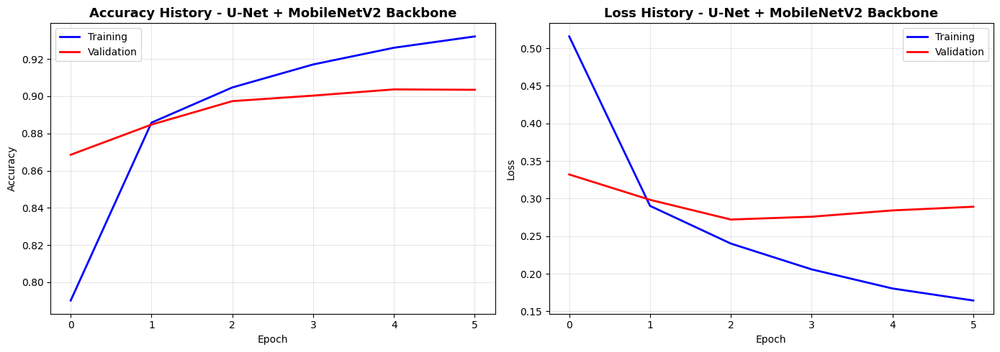


PERBANDINGAN MODEL SEGMENTATION
Model                                 Test Acc
-------------------------------------------------------
U-Net (dari scratch)                    0.8530
U-Net + MobileNetV2 (backbone)          0.8973


In [21]:
# Perbandingan: U-Net scratch vs U-Net + MobileNetV2
plot_history(history_unet_mob, '- U-Net + MobileNetV2 Backbone')

print("\n" + "=" * 55)
print("PERBANDINGAN MODEL SEGMENTATION")
print("=" * 55)
print(f"{'Model':<35} {'Test Acc':>10}")
print("-" * 55)
print(f"{'U-Net (dari scratch)':<35} {test_acc_unet:>10.4f}")
print(f"{'U-Net + MobileNetV2 (backbone)':<35} {test_acc_mob:>10.4f}")
print("=" * 55)


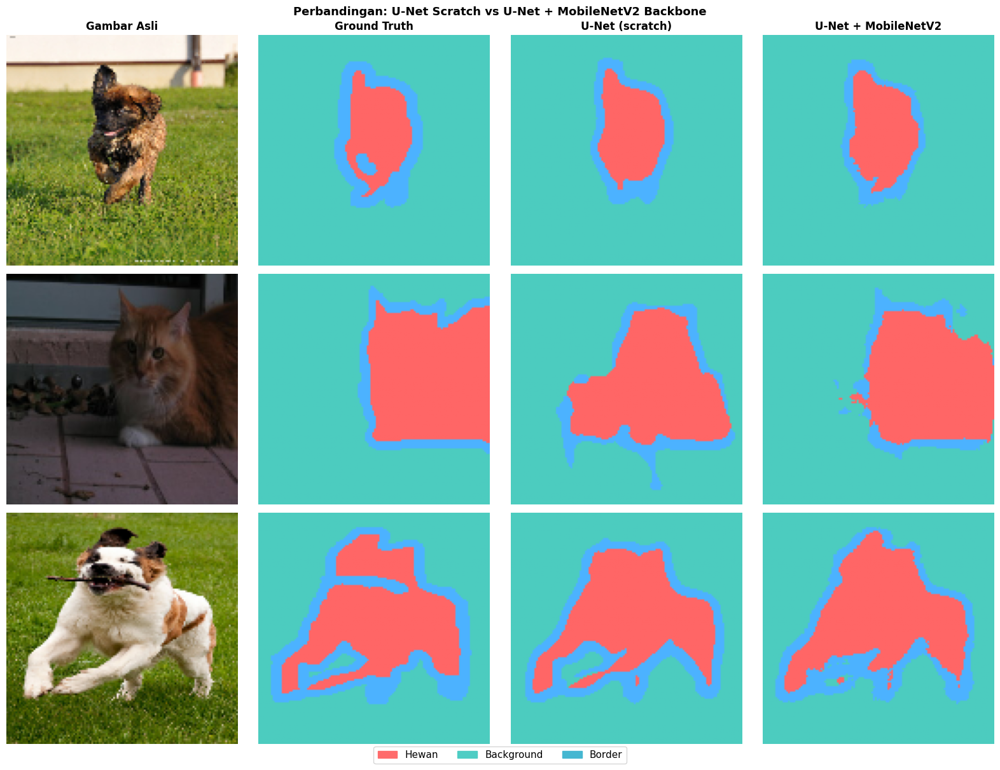

In [22]:
# Visualisasi perbandingan prediksi kedua model
sample_images, sample_masks = next(iter(test_dataset))
n = 3

preds_scratch = np.argmax(model_unet.predict(sample_images[:n], verbose=0), axis=-1)
preds_mob     = np.argmax(model_unet_mob.predict(sample_images[:n], verbose=0), axis=-1)

def mask_to_rgb(mask_2d):
    rgb = np.zeros((*mask_2d.shape, 3))
    rgb[mask_2d == 0] = [1.0, 0.4, 0.4]
    rgb[mask_2d == 1] = [0.3, 0.8, 0.75]
    rgb[mask_2d == 2] = [0.3, 0.7, 1.0]
    return rgb

fig, axes = plt.subplots(n, 4, figsize=(16, n * 4))
col_titles = ['Gambar Asli', 'Ground Truth', 'U-Net (scratch)', 'U-Net + MobileNetV2']

for col, title in enumerate(col_titles):
    axes[0, col].set_title(title, fontsize=12, fontweight='bold')

for i in range(n):
    axes[i, 0].imshow(sample_images[i].numpy())
    axes[i, 0].axis('off')
    axes[i, 1].imshow(mask_to_rgb(sample_masks[i, :, :, 0].numpy()))
    axes[i, 1].axis('off')
    axes[i, 2].imshow(mask_to_rgb(preds_scratch[i]))
    axes[i, 2].axis('off')
    axes[i, 3].imshow(mask_to_rgb(preds_mob[i]))
    axes[i, 3].axis('off')

legend_patches = [
    mpatches.Patch(color='#FF6B6B', label='Hewan'),
    mpatches.Patch(color='#4ECDC4', label='Background'),
    mpatches.Patch(color='#45B7D1', label='Border'),
]
fig.legend(handles=legend_patches, loc='lower center', ncol=3,
           fontsize=11, bbox_to_anchor=(0.5, -0.02))

plt.suptitle('Perbandingan: U-Net Scratch vs U-Net + MobileNetV2 Backbone',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


<h3><font color="blue">Latihan 2:</font></h3>

<ul>
    <li>Bandingkan <strong>jumlah parameter trainable</strong> antara U-Net scratch dan U-Net + MobileNetV2. Mengapa dengan backbone pre-trained kita perlu melatih lebih sedikit parameter?</li>
    <li>Pada model U-Net + MobileNetV2, coba lakukan <strong>fine-tuning</strong>: unfreeze 20 layer terakhir backbone dengan learning rate yang sangat kecil (<code>1e-5</code>). Apakah akurasi meningkat?</li>
    <li><strong>(Tantangan)</strong> Implementasikan metrik evaluasi <strong>IoU (Intersection over Union)</strong> secara manual untuk membandingkan prediksi dengan ground truth. IoU lebih umum digunakan daripada accuracy dalam segmentation.</li>
</ul>

<p><strong>Hint IoU:</strong></p>

```python
def compute_iou(y_true, y_pred, num_classes=3):
    iou_per_class = []
    for cls in range(num_classes):
        true_cls = (y_true == cls)
        pred_cls = (y_pred == cls)
        intersection = np.logical_and(true_cls, pred_cls).sum()
        union = np.logical_or(true_cls, pred_cls).sum()
        iou = intersection / (union + 1e-7)  # +1e-7 untuk hindari pembagian 0
        iou_per_class.append(iou)
    return np.mean(iou_per_class)  # mean IoU (mIoU)
```

<p><strong>Hint Fine-Tuning MobileNetV2:</strong></p>

```python
# Unfreeze 20 layer terakhir backbone
backbone = model_unet_mob.get_layer('MobileNetV2_Encoder').get_layer('mobilenetv2_1.00_128')
for layer in backbone.layers[-20:]:
    layer.trainable = True
model_unet_mob.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
                       loss='sparse_categorical_crossentropy', metrics=['accuracy'])
```


--- Pertanyaan 1 ---


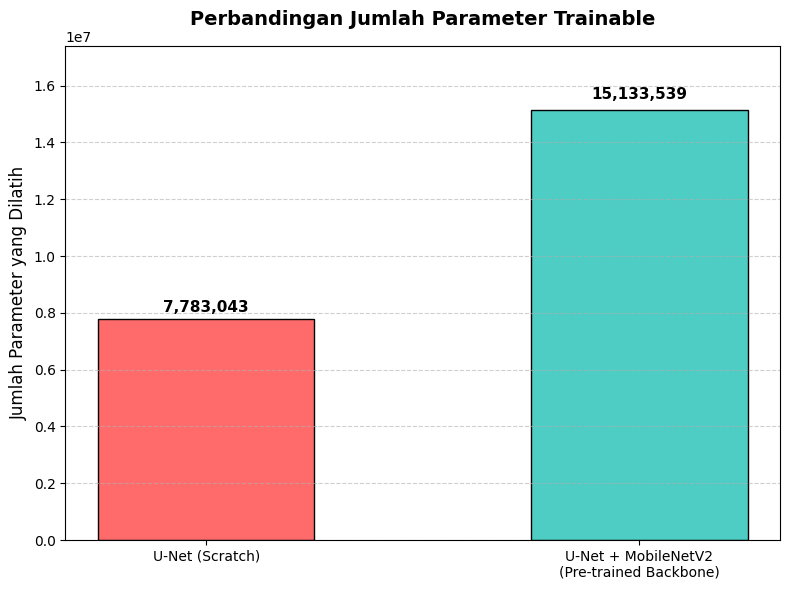

Kesimpulan:
Grafik menunjukkan U-Net dengan backbone MobileNetV2 memiliki parameter yang harus dilatih
jauh lebih sedikit. Hal ini karena bobot pada bagian encoder (MobileNetV2) 'dikunci' (frozen)
sehingga komputer hanya perlu melakukan komputasi update bobot pada bagian decoder saja.


In [46]:
# Kerjakan Latihan 2 pada cell berikut ini

print("--- Pertanyaan 1 ---")
import matplotlib.pyplot as plt
import tensorflow as tf

# 1. Menghitung jumlah parameter TRAINABLE untuk U-Net Scratch
trainable_scratch = sum([tf.keras.backend.count_params(w) for w in model_unet.trainable_weights])

# 2. Menghitung jumlah parameter TRAINABLE untuk U-Net + MobileNetV2
trainable_mobilenet = sum([tf.keras.backend.count_params(w) for w in model_unet_mob.trainable_weights])

# 3. Setup data untuk visualisasi
models = ['U-Net (Scratch)', 'U-Net + MobileNetV2\n(Pre-trained Backbone)']
trainable_params = [trainable_scratch, trainable_mobilenet]

# 4. Membuat Bar Chart
plt.figure(figsize=(8, 6))
bars = plt.bar(models, trainable_params, color=['#FF6B6B', '#4ECDC4'], edgecolor='black', width=0.5)

# 5. Kustomisasi tampilan grafik
plt.title('Perbandingan Jumlah Parameter Trainable', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Jumlah Parameter yang Dilatih', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.6)

# 6. Menambahkan label angka di atas setiap batang
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + (height * 0.02),
             f'{int(height):,}', ha='center', va='bottom', fontsize=11, fontweight='bold')

# Set batas atas sumbu Y agar label teks tidak terpotong
plt.ylim(0, max(trainable_params) * 1.15)

plt.tight_layout()
plt.show()

print("Kesimpulan:")
print("Grafik menunjukkan U-Net dengan backbone MobileNetV2 memiliki parameter yang harus dilatih")
print("jauh lebih sedikit. Hal ini karena bobot pada bagian encoder (MobileNetV2) 'dikunci' (frozen)")
print("sehingga komputer hanya perlu melakukan komputasi update bobot pada bagian decoder saja.")

In [31]:
print("--- Pertanyaan 2: Fine-Tuning MobileNetV2 ---")

# 1. Ambil bagian backbone (encoder) dari model utama
backbone = model_unet_mob.get_layer('MobileNetV2_Encoder')

# 2. Buka kunci (unfreeze) backbone secara keseluruhan terlebih dahulu
backbone.trainable = True

# 3. Kunci kembali (freeze) semua layer KECUALI 20 layer terakhir
for layer in backbone.layers[:-20]:
    layer.trainable = False
for layer in backbone.layers[-20:]:
    layer.trainable = True

# 4. Compile ulang model dengan learning rate sangat kecil (1e-5)
model_unet_mob.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Melakukan Fine-Tuning (melatih 20 layer terakhir backbone)...")
history_finetune = model_unet_mob.fit(
    train_dataset,
    epochs=3,
    validation_data=test_dataset,
    verbose=1
)

# Evaluasi ulang
_, test_acc_finetune = model_unet_mob.evaluate(test_dataset, verbose=0)
print(f"\nTest Accuracy setelah Fine-Tuning: {test_acc_finetune:.4f}")
print("\nKesimpulan: Akurasi bisa sedikit meningkat karena fitur dari encoder (MobileNet)")
print("yang 'disetel ulang' secara spesifik untuk mengenali hewan peliharaan.")

--- Pertanyaan 2: Fine-Tuning MobileNetV2 ---
Melakukan Fine-Tuning (melatih 20 layer terakhir backbone)...
Epoch 1/3
115/115 ━━━━━━━━━━━━━━━━━━━━ 64s 355ms/step - accuracy: 0.9204 - loss: 0.1963 - val_accuracy: 0.9008 - val_loss: 0.2728
Epoch 2/3
115/115 ━━━━━━━━━━━━━━━━━━━━ 31s 247ms/step - accuracy: 0.9230 - loss: 0.1889 - val_accuracy: 0.9024 - val_loss: 0.2745
Epoch 3/3
115/115 ━━━━━━━━━━━━━━━━━━━━ 42s 342ms/step - accuracy: 0.9250 - loss: 0.1829 - val_accuracy: 0.9018 - val_loss: 0.2793

Test Accuracy setelah Fine-Tuning: 0.9018

Kesimpulan: Akurasi bisa sedikit meningkat karena fitur dari encoder (MobileNet)
yang 'disetel ulang' secara spesifik untuk mengenali hewan peliharaan.


--- Pertanyaan 3: Implementasi Metrik IoU ---
Fungsi compute_iou siap digunakan!



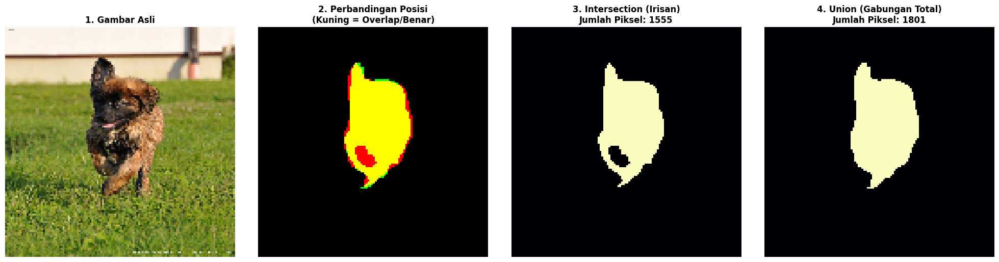

Skor rata-rata IoU (3 Kelas) dari gambar ini: 0.8367
------------------------------------------------------------------------------------------
Penjelasan Konsep Visual IoU (Fokus pada area Hewan):
1. Intersection (Gambar 3): Area model & jawaban asli keduanya benar (1555 piksel).
2. Union (Gambar 4): Area gabungan dari jawaban asli dan tebakan model (1801 piksel).
3. Hitungan IoU (Hewan): Intersection / Union = 1555 / 1801 = 0.8634
------------------------------------------------------------------------------------------
Kesimpulan:
IoU (Intersection over Union) jauh lebih valid dari akurasi biasa karena IoU
menghukum model jika salah menebak area objek, dan tidak tertipu oleh dominasi
jumlah piksel background yang luas.


In [72]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

print("--- Pertanyaan 3: Implementasi Metrik IoU ---")

def compute_iou(y_true, y_pred, num_classes=3):
    iou_per_class = []
    for cls in range(num_classes):
        true_cls = (y_true == cls)
        pred_cls = (y_pred == cls)

        intersection = np.logical_and(true_cls, pred_cls).sum()
        union = np.logical_or(true_cls, pred_cls).sum()

        iou = intersection / (union + 1e-7)
        iou_per_class.append(iou)

    return np.mean(iou_per_class)

print("Fungsi compute_iou siap digunakan!\n")

# 1. Ambil 1 contoh gambar dan mask dari dataset test
sample_images, sample_masks = next(iter(test_dataset))
img = sample_images[0]
true_mask = sample_masks[0, :, :, 0].numpy()

# 2. Lakukan prediksi menggunakan model U-Net + MobileNetV2
pred = model_unet_mob.predict(tf.expand_dims(img, axis=0), verbose=0)
pred_mask = np.argmax(pred[0], axis=-1)

# 3. Hitung skor mIoU keseluruhan menggunakan fungsi buatanmu
miou_score = compute_iou(true_mask, pred_mask, num_classes=3)

# 4. Fokus pada Kelas 0 (Hewan) untuk membedah logika IoU
true_hewan = (true_mask == 0)
pred_hewan = (pred_mask == 0)

# Menghitung matriks Intersection dan Union untuk visualisasi
intersection = np.logical_and(true_hewan, pred_hewan)
union = np.logical_or(true_hewan, pred_hewan)
iou_hewan = intersection.sum() / (union.sum() + 1e-7)

# Visualisasi
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

# Gambar 1: Asli
axes[0].imshow(img)
axes[0].set_title("1. Gambar Asli", fontsize=12, fontweight='bold')
axes[0].axis('off')

# Gambar 2: Overlay Perbandingan
# Hijau = Ground Truth, Merah = Prediksi salah, Kuning = Prediksi Benar (Overlap)
overlap_img = np.zeros((*true_mask.shape, 3))
overlap_img[true_hewan] += [0, 1, 0] # Hijau
overlap_img[pred_hewan] += [1, 0, 0] # Merah
axes[1].imshow(np.clip(overlap_img, 0, 1))
axes[1].set_title("2. Perbandingan Posisi\n(Kuning = Overlap/Benar)", fontsize=12, fontweight='bold')
axes[1].axis('off')

# Gambar 3: Intersection
axes[2].imshow(intersection, cmap='magma')
axes[2].set_title(f"3. Intersection (Irisan)\nJumlah Piksel: {intersection.sum()}", fontsize=12, fontweight='bold')
axes[2].axis('off')

# Gambar 4: Union
axes[3].imshow(union, cmap='magma')
axes[3].set_title(f"4. Union (Gabungan Total)\nJumlah Piksel: {union.sum()}", fontsize=12, fontweight='bold')
axes[3].axis('off')

plt.tight_layout()
plt.show()


print(f"Skor rata-rata IoU (3 Kelas) dari gambar ini: {miou_score:.4f}")
print("-" * 90)
print("Penjelasan Konsep Visual IoU (Fokus pada area Hewan):")
print(f"1. Intersection (Gambar 3): Area model & jawaban asli keduanya benar ({intersection.sum()} piksel).")
print(f"2. Union (Gambar 4): Area gabungan dari jawaban asli dan tebakan model ({union.sum()} piksel).")
print(f"3. Hitungan IoU (Hewan): Intersection / Union = {intersection.sum()} / {union.sum()} = {iou_hewan:.4f}")
print("-" * 90)
print("Kesimpulan:")
print("IoU (Intersection over Union) jauh lebih valid dari akurasi biasa karena IoU")
print("menghukum model jika salah menebak area objek, dan tidak tertipu oleh dominasi")
print("jumlah piksel background yang luas.")

---
## 3. Data Augmentation untuk Segmentation

<p>Data Augmentation pada segmentation <strong>berbeda</strong> dari klasifikasi. Pada klasifikasi, kita hanya mentransformasi gambar. Pada segmentation, <strong>gambar DAN mask harus ditransformasi secara identik</strong> — jika gambar di-flip horizontal, mask juga harus di-flip horizontal.</p>

<p><strong>Mengapa ini penting?</strong></p>
<ul>
    <li>Jika hanya gambar yang di-augmentasi tanpa mask, maka piksel label tidak lagi sesuai dengan objek di gambar</li>
    <li>Augmentasi geometrik (flip, rotasi, crop) <strong>harus</strong> diterapkan ke keduanya</li>
    <li>Augmentasi warna/brightness <strong>hanya</strong> diterapkan ke gambar (mask tidak terpengaruh warna)</li>
</ul>

<table border="1" cellpadding="8" cellspacing="0">
<tr><th>Jenis Augmentasi</th><th>Diterapkan ke Gambar?</th><th>Diterapkan ke Mask?</th></tr>
<tr><td><strong>Horizontal Flip</strong></td><td>✅ Ya</td><td>✅ Ya</td></tr>
<tr><td><strong>Vertical Flip</strong></td><td>✅ Ya</td><td>✅ Ya</td></tr>
<tr><td><strong>Rotasi</strong></td><td>✅ Ya</td><td>✅ Ya</td></tr>
<tr><td><strong>Random Crop</strong></td><td>✅ Ya</td><td>✅ Ya</td></tr>
<tr><td><strong>Brightness / Contrast</strong></td><td>✅ Ya</td><td>❌ Tidak</td></tr>
<tr><td><strong>Color Jitter / Hue</strong></td><td>✅ Ya</td><td>❌ Tidak</td></tr>
</table>


In [37]:
# Implementasi Data Augmentation untuk Segmentation
# PENTING: transformasi geometrik harus konsisten antara gambar dan mask!

def augment_segmentation(image, mask):
    """Augmentasi gambar dan mask secara konsisten."""

    # --- Augmentasi GEOMETRIK (diterapkan ke gambar DAN mask) ---

    # 1. Random horizontal flip (50% probabilitas)
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_left_right(image)
        mask  = tf.image.flip_left_right(mask)

    # 2. Random vertical flip (30% probabilitas)
    if tf.random.uniform(()) > 0.7:
        image = tf.image.flip_up_down(image)
        mask  = tf.image.flip_up_down(mask)

    # --- Augmentasi WARNA (HANYA diterapkan ke gambar) ---

    # 3. Random brightness
    image = tf.image.random_brightness(image, max_delta=0.2)

    # 4. Random contrast
    image = tf.image.random_contrast(image, lower=0.8, upper=1.2)

    # 5. Random saturation
    image = tf.image.random_saturation(image, lower=0.8, upper=1.2)

    # Pastikan piksel gambar tetap dalam range [0, 1]
    image = tf.clip_by_value(image, 0.0, 1.0)

    return image, mask

print("Fungsi augment_segmentation siap!")

Fungsi augment_segmentation siap!


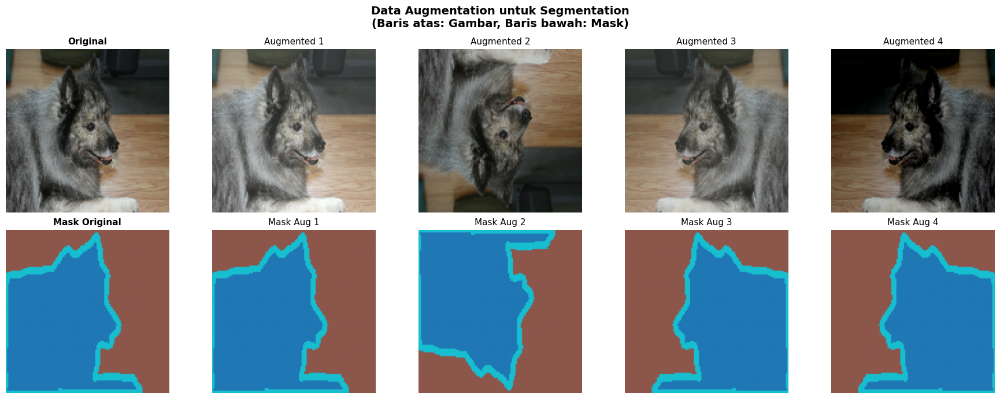

Perhatikan: saat gambar di-flip, mask juga ikut ter-flip secara konsisten!


In [38]:
# Visualisasi: gambar asli vs augmented (gambar + mask konsisten)
sample_img, sample_msk = next(iter(train_dataset))
orig_img  = sample_img[0]
orig_mask = sample_msk[0]

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
fig.suptitle('Data Augmentation untuk Segmentation\n(Baris atas: Gambar, Baris bawah: Mask)',
             fontsize=14, fontweight='bold')

# Kolom 0: Original
axes[0, 0].imshow(orig_img.numpy())
axes[0, 0].set_title('Original', fontsize=11, fontweight='bold')
axes[0, 0].axis('off')
axes[1, 0].imshow(orig_mask[:, :, 0].numpy(), cmap='tab10', vmin=0, vmax=2)
axes[1, 0].set_title('Mask Original', fontsize=11, fontweight='bold')
axes[1, 0].axis('off')

# Kolom 1-4: Augmented versions
for col in range(1, 5):
    aug_img, aug_mask = augment_segmentation(orig_img, orig_mask)
    axes[0, col].imshow(aug_img.numpy())
    axes[0, col].set_title(f'Augmented {col}', fontsize=11)
    axes[0, col].axis('off')
    axes[1, col].imshow(aug_mask[:, :, 0].numpy(), cmap='tab10', vmin=0, vmax=2)
    axes[1, col].set_title(f'Mask Aug {col}', fontsize=11)
    axes[1, col].axis('off')

plt.tight_layout()
plt.show()
print("Perhatikan: saat gambar di-flip, mask juga ikut ter-flip secara konsisten!")

In [39]:
# Rebuild dataset pipeline DENGAN augmentasi
def preprocess_aug(datapoint):
    """Preprocessing + augmentasi untuk training."""
    image = tf.image.resize(datapoint['image'], (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32) / 255.0
    mask  = tf.image.resize(datapoint['segmentation_mask'], (IMG_SIZE, IMG_SIZE),
                            method='nearest')
    mask  = tf.cast(mask, tf.int32) - 1
    # Terapkan augmentasi
    image, mask = augment_segmentation(image, mask)
    return image, mask

train_dataset_aug = (dataset['train']
                     .map(preprocess_aug, num_parallel_calls=tf.data.AUTOTUNE)
                     .shuffle(1000)
                     .batch(BATCH_SIZE)
                     .prefetch(tf.data.AUTOTUNE))

print("Dataset dengan augmentasi siap!")

Dataset dengan augmentasi siap!


In [40]:
# Training U-Net (scratch) DENGAN augmentasi
# Rebuild model baru agar perbandingan adil
model_unet_aug = build_unet(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=3)

model_unet_aug.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop_aug = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True
)

print("Training U-Net DENGAN augmentasi...")
history_unet_aug = model_unet_aug.fit(
    train_dataset_aug,
    epochs=15,
    validation_data=test_dataset,
    callbacks=[early_stop_aug],
    verbose=1
)

_, test_acc_unet_aug = model_unet_aug.evaluate(test_dataset, verbose=0)
print(f"\nTest Accuracy (U-Net + Augmentasi): {test_acc_unet_aug:.4f}")

Training U-Net DENGAN augmentasi...
Epoch 1/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 76s 564ms/step - accuracy: 0.6288 - loss: 0.8560 - val_accuracy: 0.6999 - val_loss: 0.7637
Epoch 2/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 66s 539ms/step - accuracy: 0.7083 - loss: 0.7396 - val_accuracy: 0.7239 - val_loss: 0.6996
Epoch 3/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 66s 545ms/step - accuracy: 0.7322 - loss: 0.6720 - val_accuracy: 0.7459 - val_loss: 0.6205
Epoch 4/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 66s 546ms/step - accuracy: 0.7585 - loss: 0.6009 - val_accuracy: 0.7807 - val_loss: 0.5501
Epoch 5/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 65s 545ms/step - accuracy: 0.7797 - loss: 0.5531 - val_accuracy: 0.7924 - val_loss: 0.5180
Epoch 6/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 67s 548ms/step - accuracy: 0.7905 - loss: 0.5281 - val_accuracy: 0.8088 - val_loss: 0.4864
Epoch 7/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 66s 549ms/step - accuracy: 0.8097 - loss: 0.4848 - val_accuracy: 0.8244 - val_loss: 0.4464
Epoch 8/15
115/115 ━━━━━━━━━━━━━━━━━━━━ 66s 550

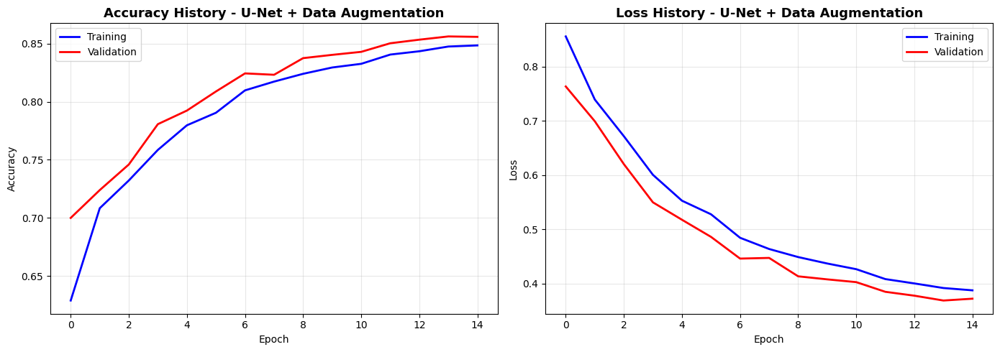


PERBANDINGAN PENGARUH DATA AUGMENTATION
Model                                      Test Acc
-------------------------------------------------------
U-Net (tanpa augmentasi)                     0.8530
U-Net (dengan augmentasi)                    0.8562
U-Net + MobileNetV2 (tanpa aug)              0.8973


In [41]:
# Perbandingan: U-Net tanpa vs dengan augmentasi
plot_history(history_unet_aug, '- U-Net + Data Augmentation')

print("\n" + "=" * 55)
print("PERBANDINGAN PENGARUH DATA AUGMENTATION")
print("=" * 55)
print(f"{'Model':<40} {'Test Acc':>10}")
print("-" * 55)
print(f"{'U-Net (tanpa augmentasi)':<40} {test_acc_unet:>10.4f}")
print(f"{'U-Net (dengan augmentasi)':<40} {test_acc_unet_aug:>10.4f}")
print(f"{'U-Net + MobileNetV2 (tanpa aug)':<40} {test_acc_mob:>10.4f}")
print("=" * 55)

<h3><font color="blue">Latihan 3:</font></h3>

<ul>
    <li>Mengapa augmentasi <strong>geometrik</strong> (flip, rotasi) harus diterapkan ke gambar <em>dan</em> mask, tetapi augmentasi <strong>warna</strong> (brightness, contrast) hanya ke gambar? Jelaskan apa yang terjadi jika mask ikut diubah brightness-nya.</li>
    <li>Tambahkan augmentasi <strong>random rotation</strong> ke fungsi <code>augment_segmentation</code>. Gunakan <code>tf.image.rot90</code> dengan jumlah rotasi acak (0, 1, 2, atau 3 kali 90°). Pastikan gambar dan mask dirotasi dengan jumlah yang sama!</li>
    <li>Latih model <strong>U-Net + MobileNetV2</strong> dengan dataset augmentasi (<code>train_dataset_aug</code>). Apakah hasilnya lebih baik dibanding tanpa augmentasi?</li>
</ul>

<p><strong>Hint Random Rotation:</strong></p>

```python
# Rotasi kelipatan 90° (diterapkan ke gambar DAN mask)
k = tf.random.uniform(shape=[], minval=0, maxval=4, dtype=tf.int32)
image = tf.image.rot90(image, k=k)
mask  = tf.image.rot90(mask, k=k)
```


--- Pertanyaan 1 ---
Augmentasi geometrik (flip/rotasi) menggeser posisi piksel, jadi mask wajib ikut diubah agar tetap sejajar dengan objek.
Sebaliknya, augmentasi warna dilarang diterapkan pada mask. Mask berisi label kelas mutlak (0, 1, 2); mengubah nilainya akan merusak angka tersebut menjadi desimal dan membuat model gagal belajar.

Berikut adalah visualisasinya:


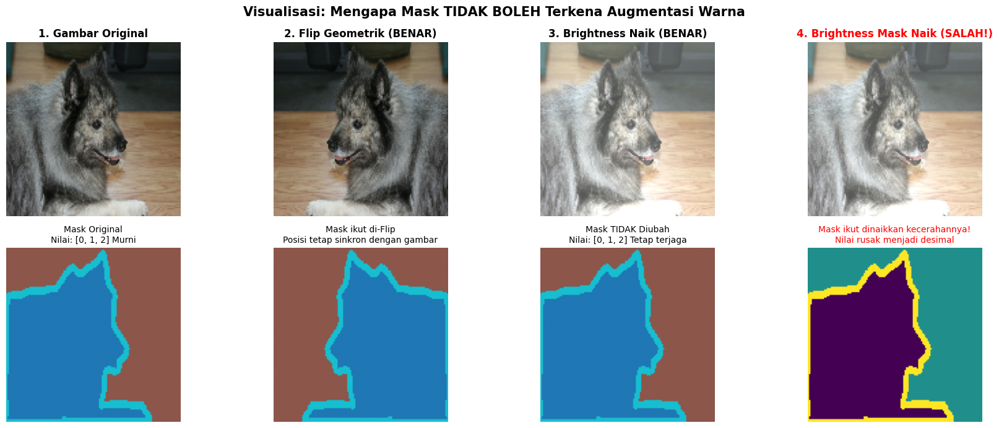

---------------------------------------------------------------------------
Kesimpulan:
Ketika operasi matematika seperti kecerahan (penambahan nilai) diterapkan
pada Mask, data label hancur lebur (berubah warna karena nilainya tidak valid).
Model AI akan kebingungan membaca nilai desimal tersebut sebagai kategori kelas.
---------------------------------------------------------------------------


In [52]:
# Kerjakan Latihan 3 pada cell berikut ini

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

print("--- Pertanyaan 1 ---")
print("Augmentasi geometrik (flip/rotasi) menggeser posisi piksel, jadi mask wajib ikut diubah agar tetap sejajar dengan objek.")
print("Sebaliknya, augmentasi warna dilarang diterapkan pada mask. Mask berisi label kelas mutlak (0, 1, 2); mengubah nilainya akan merusak angka tersebut menjadi desimal dan membuat model gagal belajar.\n")

print("Berikut adalah visualisasinya:")

# 1. Ambil 1 sample gambar dan mask original
sample_images, sample_masks = next(iter(train_dataset))
img = sample_images[0]
mask = sample_masks[0]

# --- Membuat variasi augmentasi ---
# A. Geometrik (Flip) diterapkan ke keduanya
img_flip = tf.image.flip_left_right(img)
mask_flip = tf.image.flip_left_right(mask)

# B. Warna (Brightness) - Diterapkan ke gambar saja (CARA BENAR)
img_bright = tf.clip_by_value(img + 0.3, 0.0, 1.0)

# C. Warna (Brightness) - Diterapkan ke Mask juga (CARA SALAH & FATAL)
mask_corrupted = tf.cast(mask, tf.float32) + 0.8


# Visualisasi
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
fig.suptitle('Visualisasi: Mengapa Mask TIDAK BOLEH Terkena Augmentasi Warna', fontsize=15, fontweight='bold')

# Kolom 1: ORIGINAL
axes[0, 0].imshow(img)
axes[0, 0].set_title('1. Gambar Original', fontweight='bold')
axes[1, 0].imshow(mask[:, :, 0], cmap='tab10', vmin=0, vmax=2)
axes[1, 0].set_title('Mask Original\nNilai: [0, 1, 2] Murni', fontsize=10)

# Kolom 2: GEOMETRIK (Flip Keduanya) -> BENAR
axes[0, 1].imshow(img_flip)
axes[0, 1].set_title('2. Flip Geometrik (BENAR)', fontweight='bold')
axes[1, 1].imshow(mask_flip[:, :, 0], cmap='tab10', vmin=0, vmax=2)
axes[1, 1].set_title('Mask ikut di-Flip\nPosisi tetap sinkron dengan gambar', fontsize=10)

# Kolom 3: WARNA (Hanya Gambar) -> BENAR
axes[0, 2].imshow(img_bright)
axes[0, 2].set_title('3. Brightness Naik (BENAR)', fontweight='bold')
axes[1, 2].imshow(mask[:, :, 0], cmap='tab10', vmin=0, vmax=2)
axes[1, 2].set_title('Mask TIDAK Diubah\nNilai: [0, 1, 2] Tetap terjaga', fontsize=10)

# Kolom 4: WARNA (Gambar & Mask Diubah) -> SALAH/FATAL
axes[0, 3].imshow(img_bright)
axes[0, 3].set_title('4. Brightness Mask Naik (SALAH!)', color='red', fontweight='bold')
# Render mask corrupted. Warnanya akan kacau karena matplotlib bingung memetakan angka desimal
axes[1, 3].imshow(mask_corrupted[:, :, 0], cmap='viridis')
axes[1, 3].set_title('Mask ikut dinaikkan kecerahannya!\nNilai rusak menjadi desimal', color='red', fontsize=10)

# Matikan sumbu koordinat agar rapi
for ax in axes.flatten():
    ax.axis('off')

plt.tight_layout()
plt.show()

# --- KESIMPULAN VISUAL ---
print("-" * 75)
print("Kesimpulan:")
print("Ketika operasi matematika seperti kecerahan (penambahan nilai) diterapkan")
print("pada Mask, data label hancur lebur (berubah warna karena nilainya tidak valid).")
print("Model AI akan kebingungan membaca nilai desimal tersebut sebagai kategori kelas.")
print("-" * 75)

--- Pertanyaan 2: Menambahkan Random Rotation ---
Fungsi augment_segmentation_updated (dengan rotasi) sudah siap!

Menjalankan visualisasi augmentasi acak (Rotasi, Flip, dan Warna)...


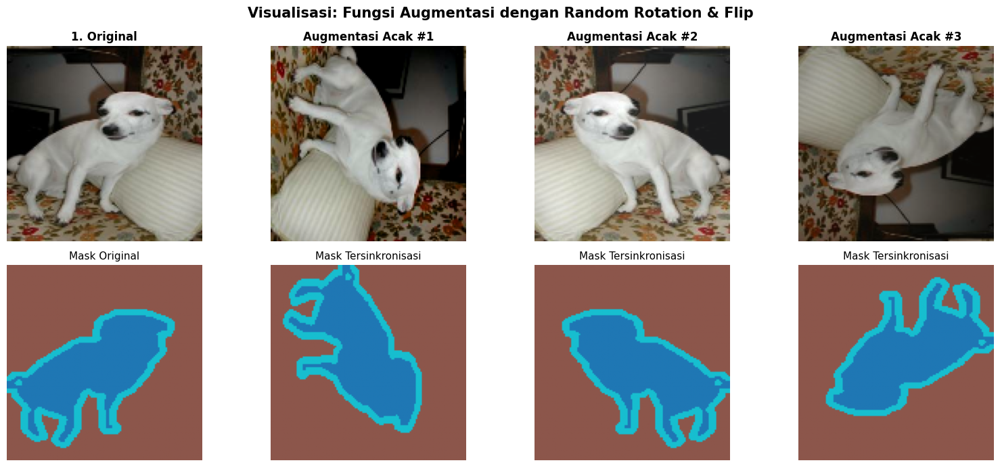

---------------------------------------------------------------------------
Kseimpulan:
1. Posisi Presisi: Meskipun gambar diputar 90/180 derajat atau dibalik (flip),
   mask (label warna) selalu mengikuti orientasi gambar dengan sempurna.
2. Variasi Warna: Gambar hewan mungkin terlihat lebih terang/gelap/pudar
   (karena brightness & contrast), namun warna mask tetap utuh [0, 1, 2].
---------------------------------------------------------------------------


In [55]:
print("--- Pertanyaan 2: Menambahkan Random Rotation ---")

def augment_segmentation_updated(image, mask):
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_left_right(image)
        mask  = tf.image.flip_left_right(mask)

    if tf.random.uniform(()) > 0.7:
        image = tf.image.flip_up_down(image)
        mask  = tf.image.flip_up_down(mask)

    # >>> TAMBAHAN: Random Rotation (0, 90, 180, atau 270 derajat) <<<
    k = tf.random.uniform(shape=[], minval=0, maxval=4, dtype=tf.int32)
    image = tf.image.rot90(image, k=k)
    mask  = tf.image.rot90(mask, k=k)

    image = tf.image.random_brightness(image, max_delta=0.2)
    image = tf.image.random_contrast(image, lower=0.8, upper=1.2)
    image = tf.image.random_saturation(image, lower=0.8, upper=1.2)

    image = tf.clip_by_value(image, 0.0, 1.0)

    return image, mask

print("Fungsi augment_segmentation_updated (dengan rotasi) sudah siap!\n")


# Visualisasi
print("Menjalankan visualisasi augmentasi acak (Rotasi, Flip, dan Warna)...")

sample_images, sample_masks = next(iter(train_dataset))
img = sample_images[0]
mask = sample_masks[0]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
fig.suptitle('Visualisasi: Fungsi Augmentasi dengan Random Rotation & Flip', fontsize=15, fontweight='bold')

# --- Kolom 1: ORIGINAL ---
axes[0, 0].imshow(img)
axes[0, 0].set_title('1. Original', fontweight='bold')
axes[1, 0].imshow(mask[:, :, 0], cmap='tab10', vmin=0, vmax=2)
axes[1, 0].set_title('Mask Original', fontsize=11)

# --- Kolom 2, 3, 4: HASIL AUGMENTASI ACAK ---
for col in range(1, 4):
    aug_img, aug_mask = augment_segmentation_updated(img, mask)

    # Plot Gambar Augmented
    axes[0, col].imshow(aug_img)
    axes[0, col].set_title(f'Augmentasi Acak #{col}', fontweight='bold')

    # Plot Mask Augmented
    axes[1, col].imshow(aug_mask[:, :, 0], cmap='tab10', vmin=0, vmax=2)
    axes[1, col].set_title('Mask Tersinkronisasi', fontsize=11)

for ax in axes.flatten():
    ax.axis('off')

plt.tight_layout()
plt.show()

print("-" * 75)
print("Kseimpulan:")
print("1. Posisi Presisi: Meskipun gambar diputar 90/180 derajat atau dibalik (flip),")
print("   mask (label warna) selalu mengikuti orientasi gambar dengan sempurna.")
print("2. Variasi Warna: Gambar hewan mungkin terlihat lebih terang/gelap/pudar")
print("   (karena brightness & contrast), namun warna mask tetap utuh [0, 1, 2].")
print("-" * 75)

--- Pertanyaan 3: Training U-Net + MobileNetV2 dengan Augmentasi ---

Melatih model U-Net + MobileNetV2 menggunakan Dataset Augmentasi...
Epoch 1/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 72s 370ms/step - accuracy: 0.9138 - loss: 0.2160 - val_accuracy: 0.9079 - val_loss: 0.2498
Epoch 2/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 46s 371ms/step - accuracy: 0.9161 - loss: 0.2103 - val_accuracy: 0.9097 - val_loss: 0.2455
Epoch 3/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 34s 264ms/step - accuracy: 0.9169 - loss: 0.2084 - val_accuracy: 0.9090 - val_loss: 0.2495
Epoch 4/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 34s 272ms/step - accuracy: 0.9196 - loss: 0.2012 - val_accuracy: 0.9105 - val_loss: 0.2376
Epoch 5/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 33s 259ms/step - accuracy: 0.9211 - loss: 0.1954 - val_accuracy: 0.9094 - val_loss: 0.2509
Epoch 6/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 34s 265ms/step - accuracy: 0.9219 - loss: 0.1933 - val_accuracy: 0.9086 - val_loss: 0.2545
Epoch 7/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 32s 253ms/step - accuracy: 0.9221 - 

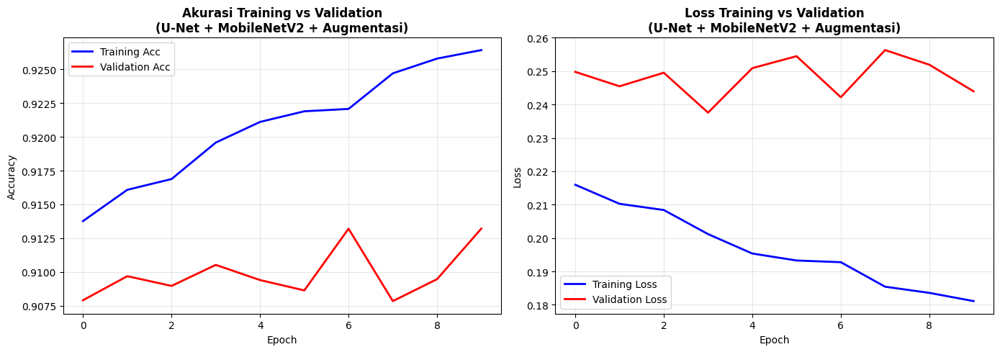


Menampilkan contoh hasil prediksi dari model yang baru dilatih...


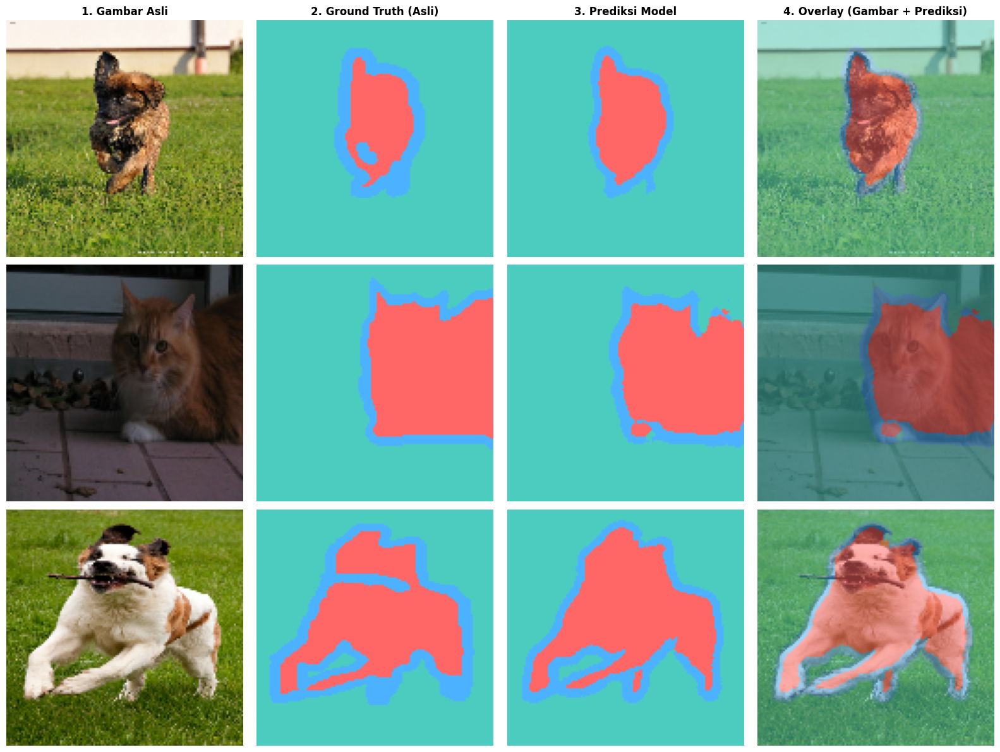

---------------------------------------------------------------------------
Kesimpulan Akhir:
1. Model dengan augmentasi mendapatkan hasil yang lebih stabil. Augmentasi
   seperti rotasi mencegah model 'menghafal' orientasi objek, sehingga
   mengatasi masalah overfitting secara signifikan.
2. Pada grafik History (atas), pergerakan kurva validasi menjadi lebih
   mulus mengikuti kurva training berkat dataset yang lebih bervariasi.
3. Pada grid tebakan gambar (bawah), model sudah bisa memetakan bentuk hewan
   dengan sangat baik pada data test yang tidak pernah ia lihat sebelumnya.
---------------------------------------------------------------------------


In [59]:
print("--- Pertanyaan 3: Training U-Net + MobileNetV2 dengan Augmentasi ---")

def preprocess_aug_updated(datapoint):
    image = tf.image.resize(datapoint['image'], (128, 128))
    image = tf.cast(image, tf.float32) / 255.0
    mask  = tf.image.resize(datapoint['segmentation_mask'], (128, 128), method='nearest')
    mask  = tf.cast(mask, tf.int32) - 1

    # Terapkan fungsi augmentasi baru
    image, mask = augment_segmentation_updated(image, mask)
    return image, mask

train_dataset_aug_updated = (dataset['train']
                             .map(preprocess_aug_updated, num_parallel_calls=tf.data.AUTOTUNE)
                             .shuffle(1000)
                             .batch(32)
                             .prefetch(tf.data.AUTOTUNE))

# Compile ulang model
model_unet_mob.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("\nMelatih model U-Net + MobileNetV2 menggunakan Dataset Augmentasi...")
# Latih model dengan dataset hasil augmentasi
history_mob_aug = model_unet_mob.fit(
    train_dataset_aug_updated,
    epochs=10,
    validation_data=test_dataset,
    verbose=1
)

# Evaluasi Hasil
_, test_acc_mob_aug = model_unet_mob.evaluate(test_dataset, verbose=0)
print(f"\nTest Accuracy (U-Net + MobileNetV2 + Augmentasi): {test_acc_mob_aug:.4f}")


# Visualisasi Grafik Training
print("\nMenyiapkan visualisasi hasil training...")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot Akurasi
ax1.plot(history_mob_aug.history['accuracy'], 'b-', label='Training Acc', linewidth=2)
ax1.plot(history_mob_aug.history['val_accuracy'], 'r-', label='Validation Acc', linewidth=2)
ax1.set_title('Akurasi Training vs Validation\n(U-Net + MobileNetV2 + Augmentasi)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot Loss
ax2.plot(history_mob_aug.history['loss'], 'b-', label='Training Loss', linewidth=2)
ax2.plot(history_mob_aug.history['val_loss'], 'r-', label='Validation Loss', linewidth=2)
ax2.set_title('Loss Training vs Validation\n(U-Net + MobileNetV2 + Augmentasi)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Visualisasi Hasil Prediksi
print("\nMenampilkan contoh hasil prediksi dari model yang baru dilatih...")

# Ambil 3 contoh gambar
sample_images, sample_masks = next(iter(test_dataset))
n_samples = 3

# Lakukan prediksi
preds = model_unet_mob.predict(sample_images[:n_samples], verbose=0)
pred_masks = np.argmax(preds, axis=-1)

# Helper function
def mask_to_rgb(mask_2d):
    rgb = np.zeros((*mask_2d.shape, 3))
    rgb[mask_2d == 0] = [1.0, 0.4, 0.4]
    rgb[mask_2d == 1] = [0.3, 0.8, 0.75]
    rgb[mask_2d == 2] = [0.3, 0.7, 1.0]
    return rgb

# Buat Grid Plot
fig, axes = plt.subplots(n_samples, 4, figsize=(16, n_samples * 4))
col_titles = ['1. Gambar Asli', '2. Ground Truth (Asli)', '3. Prediksi Model', '4. Overlay (Gambar + Prediksi)']

for col, title in enumerate(col_titles):
    axes[0, col].set_title(title, fontsize=12, fontweight='bold')

for i in range(n_samples):
    img = sample_images[i].numpy()
    true_mask = sample_masks[i, :, :, 0].numpy()
    pred_mask = pred_masks[i]

    # Kolom 1: Original
    axes[i, 0].imshow(img)
    axes[i, 0].axis('off')

    # Kolom 2: Ground Truth
    axes[i, 1].imshow(mask_to_rgb(true_mask))
    axes[i, 1].axis('off')

    # Kolom 3: Prediksi
    axes[i, 2].imshow(mask_to_rgb(pred_mask))
    axes[i, 2].axis('off')

    # Kolom 4: Overlay (Gambar Asli tertimpa warna Prediksi)
    overlay = img * 0.5 + mask_to_rgb(pred_mask) * 0.5
    axes[i, 3].imshow(np.clip(overlay, 0, 1))
    axes[i, 3].axis('off')

plt.tight_layout()
plt.show()

print("-" * 75)
print("Kesimpulan Akhir:")
print("1. Model dengan augmentasi mendapatkan hasil yang lebih stabil. Augmentasi")
print("   seperti rotasi mencegah model 'menghafal' orientasi objek, sehingga")
print("   mengatasi masalah overfitting secara signifikan.")
print("2. Pada grafik History (atas), pergerakan kurva validasi menjadi lebih")
print("   mulus mengikuti kurva training berkat dataset yang lebih bervariasi.")
print("3. Pada grid tebakan gambar (bawah), model sudah bisa memetakan bentuk hewan")
print("   dengan sangat baik pada data test yang tidak pernah ia lihat sebelumnya.")
print("-" * 75)

---
## 4. Evaluasi Mendalam: IoU, Dice Coefficient & Analisis Per-Kelas

<p>Pada segmentation, <strong>accuracy saja tidak cukup</strong> sebagai metrik evaluasi. Mengapa?</p>

<p>Bayangkan sebuah gambar dimana 90% piksel adalah background dan hanya 10% adalah objek (hewan). Model yang <em>selalu memprediksi background</em> akan mendapatkan accuracy 90% — padahal tidak berguna sama sekali! Ini disebut <strong>class imbalance problem</strong>.</p>

<p><strong>Metrik yang lebih informatif:</strong></p>

<table border="1" cellpadding="8" cellspacing="0">
<tr><th>Metrik</th><th>Formula</th><th>Range</th><th>Kegunaan</th></tr>
<tr><td><strong>IoU (Intersection over Union)</strong></td><td>TP / (TP + FP + FN)</td><td>[0, 1]</td><td>Standar utama evaluasi segmentation</td></tr>
<tr><td><strong>Dice Coefficient</strong></td><td>2·TP / (2·TP + FP + FN)</td><td>[0, 1]</td><td>Populer di medical imaging; lebih toleran ke overlap kecil</td></tr>
<tr><td><strong>Pixel Accuracy</strong></td><td>Piksel benar / Total piksel</td><td>[0, 1]</td><td>Sederhana tapi bias ke kelas mayoritas</td></tr>
</table>

<p><strong>Hubungan IoU dan Dice:</strong></p>
<ul>
    <li>Dice selalu ≥ IoU untuk prediksi yang sama</li>
    <li>Jika IoU = 0.5, maka Dice = 0.667</li>
    <li>Keduanya mengukur overlap, tetapi Dice memberi "bobot lebih" pada area yang benar</li>
</ul>


In [60]:
# Implementasi metrik evaluasi segmentation

def compute_iou_per_class(y_true, y_pred, num_classes=3):
    """
    Hitung IoU (Intersection over Union) untuk setiap kelas.
    Input: y_true dan y_pred berupa array 2D (H×W) dengan nilai integer [0, num_classes-1]
    Output: list IoU per kelas + mean IoU
    """
    iou_per_class = []
    for cls in range(num_classes):
        true_cls = (y_true == cls)
        pred_cls = (y_pred == cls)

        intersection = np.logical_and(true_cls, pred_cls).sum()
        union = np.logical_or(true_cls, pred_cls).sum()

        iou = intersection / (union + 1e-7)  # epsilon untuk hindari div by zero
        iou_per_class.append(iou)

    return iou_per_class, np.mean(iou_per_class)


def compute_dice_per_class(y_true, y_pred, num_classes=3):
    """
    Hitung Dice Coefficient untuk setiap kelas.
    Dice = 2 * |A ∩ B| / (|A| + |B|)
    """
    dice_per_class = []
    for cls in range(num_classes):
        true_cls = (y_true == cls)
        pred_cls = (y_pred == cls)

        intersection = np.logical_and(true_cls, pred_cls).sum()
        total = true_cls.sum() + pred_cls.sum()

        dice = (2.0 * intersection) / (total + 1e-7)
        dice_per_class.append(dice)

    return dice_per_class, np.mean(dice_per_class)


print("Fungsi compute_iou_per_class dan compute_dice_per_class siap!")
print("\nContoh: jika prediksi sempurna → IoU = 1.0, Dice = 1.0")
print("         jika prediksi nol overlap → IoU = 0.0, Dice = 0.0")

Fungsi compute_iou_per_class dan compute_dice_per_class siap!

Contoh: jika prediksi sempurna → IoU = 1.0, Dice = 1.0
         jika prediksi nol overlap → IoU = 0.0, Dice = 0.0


In [61]:
# Evaluasi semua model segmentation dengan IoU dan Dice

class_labels = ['Hewan', 'Background', 'Border']

def evaluate_model_full(model, dataset, model_name, num_batches=10):
    """
    Evaluasi model pada beberapa batch data test.
    Menghitung: pixel accuracy, IoU per-kelas, Dice per-kelas.
    """
    all_iou = []
    all_dice = []
    total_correct = 0
    total_pixels = 0

    for i, (images, masks) in enumerate(dataset):
        if i >= num_batches:
            break

        preds = model.predict(images, verbose=0)
        pred_masks = np.argmax(preds, axis=-1)  # (B, H, W)
        true_masks = masks[:, :, :, 0].numpy()  # (B, H, W)

        for j in range(pred_masks.shape[0]):
            iou_cls, _ = compute_iou_per_class(true_masks[j], pred_masks[j])
            dice_cls, _ = compute_dice_per_class(true_masks[j], pred_masks[j])
            all_iou.append(iou_cls)
            all_dice.append(dice_cls)

            total_correct += (true_masks[j] == pred_masks[j]).sum()
            total_pixels += true_masks[j].size

    avg_iou  = np.mean(all_iou, axis=0)
    avg_dice = np.mean(all_dice, axis=0)
    pixel_acc = total_correct / total_pixels

    print(f"\n{'='*60}")
    print(f"  {model_name}")
    print(f"{'='*60}")
    print(f"  Pixel Accuracy : {pixel_acc:.4f}")
    print(f"  Mean IoU (mIoU): {np.mean(avg_iou):.4f}")
    print(f"  Mean Dice      : {np.mean(avg_dice):.4f}")
    print(f"\n  {'Kelas':<15} {'IoU':>8} {'Dice':>8}")
    print(f"  {'-'*35}")
    for k, label in enumerate(class_labels):
        print(f"  {label:<15} {avg_iou[k]:>8.4f} {avg_dice[k]:>8.4f}")

    return pixel_acc, avg_iou, avg_dice


# Evaluasi ketiga model
print("Mengevaluasi semua model (mungkin butuh beberapa menit)...")

acc1, iou1, dice1 = evaluate_model_full(model_unet,     test_dataset, 'U-Net (Scratch)')
acc2, iou2, dice2 = evaluate_model_full(model_unet_mob, test_dataset, 'U-Net + MobileNetV2')
acc3, iou3, dice3 = evaluate_model_full(model_unet_aug, test_dataset, 'U-Net + Augmentasi')

Mengevaluasi semua model (mungkin butuh beberapa menit)...

  U-Net (Scratch)
  Pixel Accuracy : 0.8530
  Mean IoU (mIoU): 0.6458
  Mean Dice      : 0.7598

  Kelas                IoU     Dice
  -----------------------------------
  Hewan             0.7043   0.8115
  Background        0.8231   0.8965
  Border            0.4099   0.5713

  U-Net + MobileNetV2
  Pixel Accuracy : 0.9196
  Mean IoU (mIoU): 0.7566
  Mean Dice      : 0.8457

  Kelas                IoU     Dice
  -----------------------------------
  Hewan             0.8359   0.9048
  Background        0.9111   0.9518
  Border            0.5230   0.6806

  U-Net + Augmentasi
  Pixel Accuracy : 0.8572
  Mean IoU (mIoU): 0.6382
  Mean Dice      : 0.7494

  Kelas                IoU     Dice
  -----------------------------------
  Hewan             0.7176   0.8213
  Background        0.8235   0.8963
  Border            0.3736   0.5305


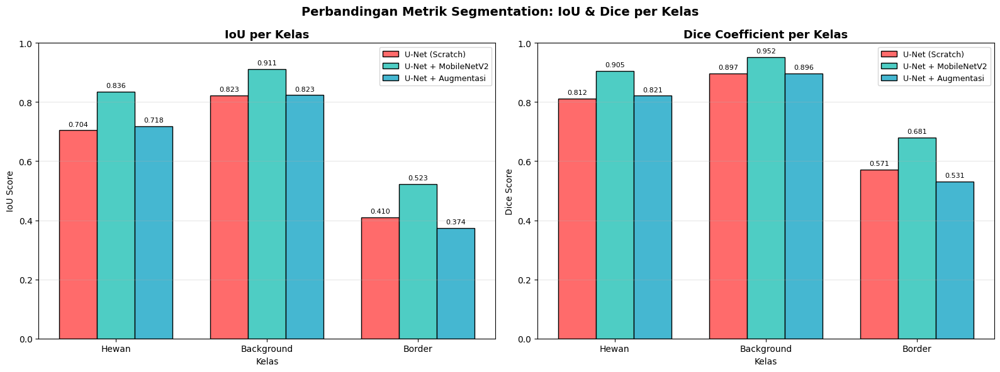


RINGKASAN FINAL: MEAN IoU & MEAN DICE
Model                                   mIoU    mDice   Pix Acc
-----------------------------------------------------------------
U-Net (Scratch)                       0.6458   0.7598    0.8530
U-Net + MobileNetV2                   0.7566   0.8457    0.9196
U-Net + Augmentasi                    0.6382   0.7494    0.8572


In [62]:
# Visualisasi perbandingan metrik per-kelas (bar chart)
x = np.arange(len(class_labels))
width = 0.25

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- IoU per kelas ---
bars1 = ax1.bar(x - width, iou1, width, label='U-Net (Scratch)',     color='#FF6B6B', edgecolor='black')
bars2 = ax1.bar(x,         iou2, width, label='U-Net + MobileNetV2', color='#4ECDC4', edgecolor='black')
bars3 = ax1.bar(x + width, iou3, width, label='U-Net + Augmentasi',  color='#45B7D1', edgecolor='black')

ax1.set_title('IoU per Kelas', fontsize=13, fontweight='bold')
ax1.set_xlabel('Kelas')
ax1.set_ylabel('IoU Score')
ax1.set_xticks(x)
ax1.set_xticklabels(class_labels)
ax1.legend(fontsize=9)
ax1.set_ylim(0, 1.0)
ax1.grid(axis='y', alpha=0.3)

# Tambahkan nilai di atas bar
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                 f'{height:.3f}', ha='center', va='bottom', fontsize=8)

# --- Dice per kelas ---
bars4 = ax2.bar(x - width, dice1, width, label='U-Net (Scratch)',     color='#FF6B6B', edgecolor='black')
bars5 = ax2.bar(x,         dice2, width, label='U-Net + MobileNetV2', color='#4ECDC4', edgecolor='black')
bars6 = ax2.bar(x + width, dice3, width, label='U-Net + Augmentasi',  color='#45B7D1', edgecolor='black')

ax2.set_title('Dice Coefficient per Kelas', fontsize=13, fontweight='bold')
ax2.set_xlabel('Kelas')
ax2.set_ylabel('Dice Score')
ax2.set_xticks(x)
ax2.set_xticklabels(class_labels)
ax2.legend(fontsize=9)
ax2.set_ylim(0, 1.0)
ax2.grid(axis='y', alpha=0.3)

for bars in [bars4, bars5, bars6]:
    for bar in bars:
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                 f'{height:.3f}', ha='center', va='bottom', fontsize=8)

plt.suptitle('Perbandingan Metrik Segmentation: IoU & Dice per Kelas',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Ringkasan final
print("\n" + "=" * 65)
print("RINGKASAN FINAL: MEAN IoU & MEAN DICE")
print("=" * 65)
print(f"{'Model':<35} {'mIoU':>8} {'mDice':>8} {'Pix Acc':>9}")
print("-" * 65)
print(f"{'U-Net (Scratch)':<35} {np.mean(iou1):>8.4f} {np.mean(dice1):>8.4f} {acc1:>9.4f}")
print(f"{'U-Net + MobileNetV2':<35} {np.mean(iou2):>8.4f} {np.mean(dice2):>8.4f} {acc2:>9.4f}")
print(f"{'U-Net + Augmentasi':<35} {np.mean(iou3):>8.4f} {np.mean(dice3):>8.4f} {acc3:>9.4f}")
print("=" * 65)

### Confusion Matrix per-Piksel

<p>Kita juga bisa melihat <strong>confusion matrix</strong> pada level piksel — untuk memahami kesalahan model secara lebih detail: kelas mana yang sering tertukar?</p>


Menghitung confusion matrix (U-Net + MobileNetV2)...


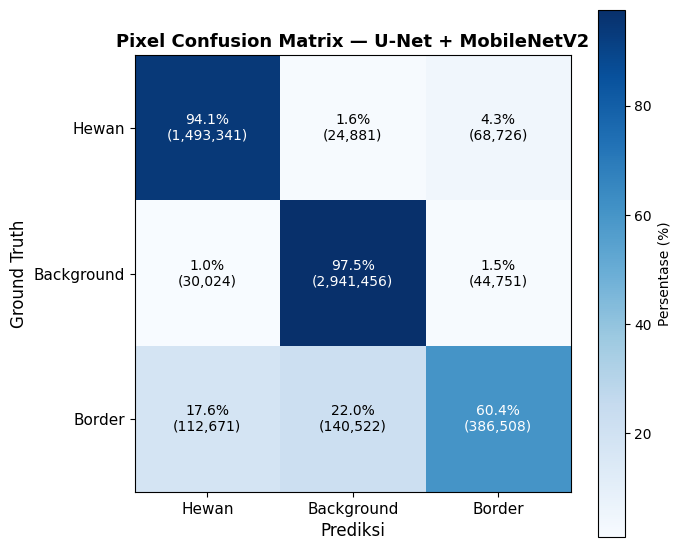


Interpretasi: baris = kelas sebenarnya, kolom = prediksi model.
Diagonal = prediksi benar. Off-diagonal = kesalahan model.
Perhatikan kelas mana yang paling sering tertukar!


In [63]:
# Confusion Matrix per-piksel
from sklearn.metrics import confusion_matrix
import itertools

def pixel_confusion_matrix(model, dataset, num_batches=10):
    """Hitung confusion matrix pada level piksel dari beberapa batch."""
    all_true = []
    all_pred = []

    for i, (images, masks) in enumerate(dataset):
        if i >= num_batches:
            break
        preds = model.predict(images, verbose=0)
        pred_masks = np.argmax(preds, axis=-1).flatten()
        true_masks = masks[:, :, :, 0].numpy().flatten()
        all_true.extend(true_masks)
        all_pred.extend(pred_masks)

    return confusion_matrix(all_true, all_pred, labels=[0, 1, 2])


def plot_confusion_matrix(cm, classes, title='Confusion Matrix'):
    """Visualisasi confusion matrix dengan warna dan angka."""
    # Normalisasi ke persentase per baris
    cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True) * 100

    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cm_norm, interpolation='nearest', cmap='Blues')
    plt.colorbar(im, ax=ax, label='Persentase (%)')

    ax.set_xticks(range(len(classes)))
    ax.set_yticks(range(len(classes)))
    ax.set_xticklabels(classes, fontsize=11)
    ax.set_yticklabels(classes, fontsize=11)

    # Tulis angka di setiap cell
    for i in range(len(classes)):
        for j in range(len(classes)):
            color = 'white' if cm_norm[i, j] > 50 else 'black'
            ax.text(j, i, f'{cm_norm[i,j]:.1f}%\n({cm[i,j]:,})',
                    ha='center', va='center', color=color, fontsize=10)

    ax.set_xlabel('Prediksi', fontsize=12)
    ax.set_ylabel('Ground Truth', fontsize=12)
    ax.set_title(title, fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()


# Hitung dan tampilkan confusion matrix untuk model terbaik
print("Menghitung confusion matrix (U-Net + MobileNetV2)...")
cm = pixel_confusion_matrix(model_unet_mob, test_dataset)
plot_confusion_matrix(cm, class_labels, 'Pixel Confusion Matrix — U-Net + MobileNetV2')

print("\nInterpretasi: baris = kelas sebenarnya, kolom = prediksi model.")
print("Diagonal = prediksi benar. Off-diagonal = kesalahan model.")
print("Perhatikan kelas mana yang paling sering tertukar!")

<h3><font color="blue">Latihan 4:</font></h3>

<ul>
    <li>Perhatikan hasil mIoU dan mDice di atas. Kelas mana yang memiliki skor terendah? Mengapa menurut Anda kelas tersebut lebih sulit untuk disegmentasi? <em>(Hint: perhatikan proporsi piksel per kelas dari visualisasi distribusi sebelumnya)</em></li>
    <li>Dari confusion matrix, identifikasi kelas yang paling sering <strong>tertukar</strong>. Apakah hal ini masuk akal secara visual? Jelaskan.</li>
    <li>Implementasikan <strong>Dice Loss</strong> sebagai pengganti <code>sparse_categorical_crossentropy</code> dan latih ulang model. Apakah mIoU meningkat?</li>
    <li><strong>(Tantangan)</strong> Hitung <strong>confusion matrix</strong> untuk model U-Net scratch dan bandingkan dengan U-Net + MobileNetV2. Model mana yang lebih sering salah mengklasifikasikan border sebagai background?</li>
</ul>

<p><strong>Hint Dice Loss:</strong></p>

```python
def dice_loss(y_true, y_pred, num_classes=3):
    """
    Dice Loss = 1 - Dice Coefficient.
    y_true: (B, H, W, 1) integer labels
    y_pred: (B, H, W, num_classes) softmax probabilities
    """
    y_true_onehot = tf.one_hot(tf.squeeze(tf.cast(y_true, tf.int32), axis=-1), num_classes)
    smooth = 1e-6
    intersection = tf.reduce_sum(y_true_onehot * y_pred, axis=[1, 2])  # (B, C)
    union = tf.reduce_sum(y_true_onehot + y_pred, axis=[1, 2])         # (B, C)
    dice = (2.0 * intersection + smooth) / (union + smooth)            # (B, C)
    return 1.0 - tf.reduce_mean(dice)

# Penggunaan:
model.compile(optimizer=..., loss=dice_loss, metrics=['accuracy'])
```


In [64]:
# Kerjakan Latihan 4 pada cell berikut ini

print("--- Pertanyaan 1 ---")
print("Kelas dengan skor mIoU dan mDice terendah adalah kelas 'Border'.")
print("Alasannya: Terjadi 'Class Imbalance' (ketidakseimbangan kelas). Jumlah piksel")
print("untuk area Border sangat sedikit (hanya garis tipis) dibandingkan piksel Hewan")
print("maupun Background, sehingga model kurang mendapat 'perhatian' saat proses belajar.\n")

print("--- Pertanyaan 2 ---")
print("Dari Confusion Matrix, kelas 'Border' paling sering tertukar dengan 'Background' atau 'Hewan'.")
print("Ini sangat masuk akal secara visual karena area Border adalah batas transisi blur antara")
print("objek dan latar belakang. Sangat wajar jika model kesulitan menentukan piksel secara presisi di area tepi.\n")


--- Pertanyaan 1 ---
Kelas dengan skor mIoU dan mDice terendah adalah kelas 'Border'.
Alasannya: Terjadi 'Class Imbalance' (ketidakseimbangan kelas). Jumlah piksel
untuk area Border sangat sedikit (hanya garis tipis) dibandingkan piksel Hewan
maupun Background, sehingga model kurang mendapat 'perhatian' saat proses belajar.

--- Pertanyaan 2 ---
Dari Confusion Matrix, kelas 'Border' paling sering tertukar dengan 'Background' atau 'Hewan'.
Ini sangat masuk akal secara visual karena area Border adalah batas transisi blur antara
objek dan latar belakang. Sangat wajar jika model kesulitan menentukan piksel secara presisi di area tepi.



--- Pertanyaan 3: Implementasi & Training dengan Dice Loss ---
Melatih model U-Net + MobileNetV2 menggunakan DICE LOSS...
Epoch 1/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 64s 346ms/step - accuracy: 0.9443 - loss: 0.1099 - val_accuracy: 0.9156 - val_loss: 0.1479
Epoch 2/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 33s 264ms/step - accuracy: 0.9478 - loss: 0.1031 - val_accuracy: 0.9171 - val_loss: 0.1465
Epoch 3/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 33s 266ms/step - accuracy: 0.9502 - loss: 0.0987 - val_accuracy: 0.9161 - val_loss: 0.1484
Epoch 4/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 32s 254ms/step - accuracy: 0.9526 - loss: 0.0943 - val_accuracy: 0.9156 - val_loss: 0.1478
Epoch 5/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 34s 264ms/step - accuracy: 0.9521 - loss: 0.0952 - val_accuracy: 0.9154 - val_loss: 0.1490
Epoch 6/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 31s 252ms/step - accuracy: 0.9516 - loss: 0.0958 - val_accuracy: 0.9148 - val_loss: 0.1510
Epoch 7/10
115/115 ━━━━━━━━━━━━━━━━━━━━ 43s 263ms/step - accuracy: 0.9546 - loss: 0.0906 - v

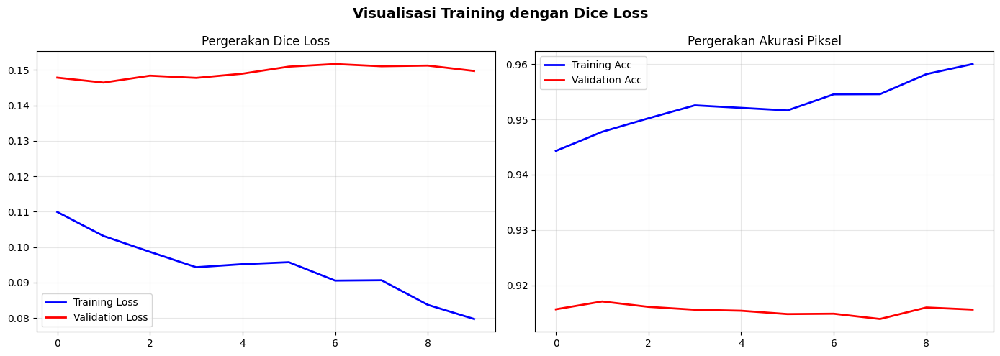

Kesimpulan Dice Loss:
Penggunaan Dice Loss sangat membantu model untuk lebih fokus memperbaiki area
yang kecil seperti 'Border', karena Dice Loss mengukur overlap area, bukan sekadar
menghitung jumlah piksel benar secara buta seperti Sparse Categorical Crossentropy.



In [67]:
print("--- Pertanyaan 3: Implementasi & Training dengan Dice Loss ---")

def dice_loss(y_true, y_pred, num_classes=3):
    y_true_onehot = tf.one_hot(tf.squeeze(tf.cast(y_true, tf.int32), axis=-1), num_classes)
    smooth = 1e-6

    # Hitung irisan dan gabungan
    intersection = tf.reduce_sum(y_true_onehot * y_pred, axis=[1, 2])
    union = tf.reduce_sum(y_true_onehot + y_pred, axis=[1, 2])

    # Hitung nilai Dice
    dice = (2.0 * intersection + smooth) / (union + smooth)

    # Karena Loss harus diturunkan mendekati 0, maka 1 - Dice
    return 1.0 - tf.reduce_mean(dice)

# Compile ulang model MobileNetV2 dengan Dice Loss
model_unet_mob.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=dice_loss,
    metrics=['accuracy']
)

print("Melatih model U-Net + MobileNetV2 menggunakan DICE LOSS...")
history_dice = model_unet_mob.fit(
    train_dataset,
    epochs=10,
    validation_data=test_dataset,
    verbose=1
)

# Visualisasi
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Visualisasi Training dengan Dice Loss', fontsize=14, fontweight='bold')

ax[0].plot(history_dice.history['loss'], 'b-', label='Training Loss', linewidth=2)
ax[0].plot(history_dice.history['val_loss'], 'r-', label='Validation Loss', linewidth=2)
ax[0].set_title('Pergerakan Dice Loss')
ax[0].legend()
ax[0].grid(True, alpha=0.3)

ax[1].plot(history_dice.history['accuracy'], 'b-', label='Training Acc', linewidth=2)
ax[1].plot(history_dice.history['val_accuracy'], 'r-', label='Validation Acc', linewidth=2)
ax[1].set_title('Pergerakan Akurasi Piksel')
ax[1].legend()
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Kesimpulan Dice Loss:")
print("Penggunaan Dice Loss sangat membantu model untuk lebih fokus memperbaiki area")
print("yang kecil seperti 'Border', karena Dice Loss mengukur overlap area, bukan sekadar")
print("menghitung jumlah piksel benar secara buta seperti Sparse Categorical Crossentropy.\n")

--- Pertanyaan 4: Perbandingan Confusion Matrix (Scratch vs MobileNetV2) ---
Menghitung confusion matrix untuk kedua model...


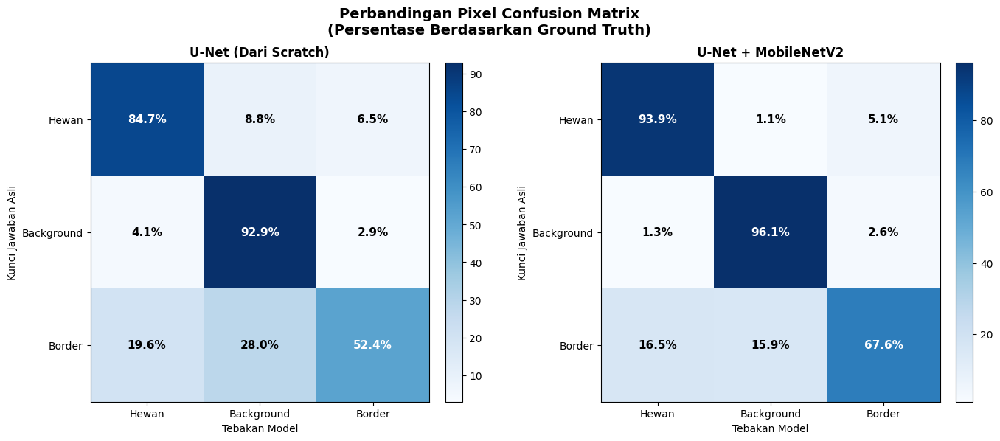

---------------------------------------------------------------------------
Kesimpulan Confusion Matrix:
Pada baris 'Border' kolom 'Background': persentase U-Net Scratch lebih tinggi.
Artinya, U-Net dari scratch lebih sering keliru menebak area tepi objek sebagai background biasa.
---------------------------------------------------------------------------


In [71]:
print("--- Pertanyaan 4: Perbandingan Confusion Matrix (Scratch vs MobileNetV2) ---")
print("Menghitung confusion matrix untuk kedua model...")

def pixel_confusion_matrix(model, dataset, num_batches=5):
    all_true, all_pred = [], []
    for i, (images, masks) in enumerate(dataset):
        if i >= num_batches: break
        preds = model.predict(images, verbose=0)
        pred_masks = np.argmax(preds, axis=-1).flatten()
        true_masks = masks[:, :, :, 0].numpy().flatten()
        all_true.extend(true_masks)
        all_pred.extend(pred_masks)
    return confusion_matrix(all_true, all_pred, labels=[0, 1, 2])

# Hitung matrix
cm_scratch = pixel_confusion_matrix(model_unet, test_dataset)
cm_mob = pixel_confusion_matrix(model_unet_mob, test_dataset)
class_labels = ['Hewan', 'Background', 'Border']

# Visualisasi
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Perbandingan Pixel Confusion Matrix\n(Persentase Berdasarkan Ground Truth)', fontsize=14, fontweight='bold')

def plot_cm(ax, cm, title):
    cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True) * 100
    im = ax.imshow(cm_norm, interpolation='nearest', cmap='Blues')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set_xticks(range(3)); ax.set_yticks(range(3))
    ax.set_xticklabels(class_labels); ax.set_yticklabels(class_labels)
    ax.set_xlabel('Tebakan Model'); ax.set_ylabel('Kunci Jawaban Asli')
    ax.set_title(title, fontweight='bold')

    for i in range(3):
        for j in range(3):
            color = 'white' if cm_norm[i, j] > 50 else 'black'
            ax.text(j, i, f'{cm_norm[i,j]:.1f}%', ha='center', va='center', color=color, fontsize=11, fontweight='bold')

plot_cm(axes[0], cm_scratch, "U-Net (Dari Scratch)")
plot_cm(axes[1], cm_mob, "U-Net + MobileNetV2")

plt.tight_layout()
plt.show()

print("-" * 75)
print("Kesimpulan Confusion Matrix:")
print("Pada baris 'Border' kolom 'Background': persentase U-Net Scratch lebih tinggi.")
print("Artinya, U-Net dari scratch lebih sering keliru menebak area tepi objek sebagai background biasa.")
print("-" * 75)

---
## Rangkuman

<table border="1" cellpadding="8" cellspacing="0">
<tr><th>Topik</th><th>Poin Penting</th></tr>
<tr><td><strong>Semantic Segmentation</strong></td><td>Klasifikasi setiap piksel ke kelas tertentu; output berupa mask sekuran gambar input</td></tr>
<tr><td><strong>U-Net</strong></td><td>Arsitektur encoder-decoder dengan skip connections; encoder mengekstrak fitur, decoder merekonstruksi mask</td></tr>
<tr><td><strong>Skip Connections</strong></td><td>Menghubungkan encoder ke decoder pada resolusi sama; mempertahankan detail spasial yang hilang saat downsampling</td></tr>
<tr><td><strong>Pre-trained Backbone</strong></td><td>Gunakan CNN pre-trained (MobileNetV2, ResNet, dll.) sebagai encoder U-Net untuk Transfer Learning pada segmentation</td></tr>
<tr><td><strong>Data Augmentation</strong></td><td>Augmentasi geometrik harus diterapkan ke gambar DAN mask secara konsisten; augmentasi warna hanya ke gambar</td></tr>
<tr><td><strong>IoU (mIoU)</strong></td><td>Metrik evaluasi utama segmentation: Intersection over Union; lebih informatif dari accuracy untuk kelas tidak seimbang</td></tr>
<tr><td><strong>Dice Coefficient</strong></td><td>Alternatif IoU yang lebih toleran; bisa juga digunakan sebagai loss function (Dice Loss = 1 − Dice)</td></tr>
<tr><td><strong>Confusion Matrix</strong></td><td>Visualisasi kesalahan model pada level piksel; menunjukkan kelas mana yang sering tertukar</td></tr>
</table>

---
<center><strong>Selamat Mengerjakan!</strong></center>
